# 20260317 Muscat: Feronia salinity time course data (using the newly integrated seurat 3 obj of sc 291 ~ 294, confirmed NO suspicious cluster)
This runs within the muscat Conda environment

In [1]:
# Check the conda env running, it's important that you're running in the correct conda env
# Don't change anything here
Sys.getenv("CONDA_DEFAULT_ENV")

[1] "muscat"

In [2]:
# Check Seurat version, it's important that you're using the correct version of Seurat
# scKB_copilot: Seurat 3; seu4_label_transfer: Seurat 4; muscat: Seurat 5
# Don't change anything here
packageVersion("Seurat")

[1] ‘5.2.1’

In [3]:
# Clean the environment and set the directory
# Change the directory to your project folder under your name
rm(list=ls())
# NOTE: lab cluster path below -- change it to your own path
setwd("/resnick/groups/NolanLab/cchen/Feronia/analysis")

In [4]:
# Load the libraries
# Don't change anything here
suppressMessages(library(tidyverse))
suppressMessages(library(Seurat))
suppressMessages(library(cowplot))
suppressMessages(library(future))
suppressMessages(library(grid))
suppressMessages(library(gridExtra))
suppressMessages(library(circlize))
suppressMessages(library(gprofiler2))
# Pin g:Profiler to the archived release that produced the published GO results
# (Ensembl 113 / Ensembl Genomes 59; reproduces the GO tables exactly). The live server changes over time.
gprofiler2::set_base_url("https://biit.cs.ut.ee/gprofiler_archive3/e113_eg59_p19")
suppressMessages(library(ggrepel))
suppressMessages(library(ggplot2))
suppressMessages(library(data.table))
suppressMessages(library(muscat))
suppressMessages(library(purrr))
suppressMessages(library(GeneOverlap))
suppressMessages(library(ComplexHeatmap))
suppressMessages(library(limma))
suppressMessages(library(scran))
suppressMessages(library(ggplot2))
suppressMessages(library(patchwork))

suppressMessages(library(proxy))
# suppressMessages(library(matlab))
suppressMessages(library(Matrix))


In [5]:
# Check the loaded packages and their versions. 
# # Be sure to execute this! It's important for reproducibility and debugging
# Don't change anything here
sessionInfo()

R version 4.3.3 (2024-02-29)
Platform: x86_64-conda-linux-gnu (64-bit)
Running under: Red Hat Enterprise Linux 9.5 (Plow)

Matrix products: default
BLAS/LAPACK: /resnick/groups/NolanLab/cchen/miniconda3/envs/muscat/lib/libopenblasp-r0.3.27.so;  LAPACK version 3.12.0

locale:
 [1] LC_CTYPE=en_US.UTF-8       LC_NUMERIC=C              
 [3] LC_TIME=en_US.UTF-8        LC_COLLATE=en_US.UTF-8    
 [5] LC_MONETARY=en_US.UTF-8    LC_MESSAGES=en_US.UTF-8   
 [7] LC_PAPER=en_US.UTF-8       LC_NAME=C                 
 [9] LC_ADDRESS=C               LC_TELEPHONE=C            
[11] LC_MEASUREMENT=en_US.UTF-8 LC_IDENTIFICATION=C       

time zone: America/Los_Angeles
tzcode source: system (glibc)

attached base packages:
[1] stats4    grid      stats     graphics  grDevices utils     datasets 
[8] methods   base     

other attached packages:
 [1] Matrix_1.6-5                proxy_0.4-27               
 [3] patchwork_1.3.0             scran_1.30.2               
 [5] scuttle_1.12.0              Sing

In [6]:
# The function to read Seurat object
# This is specifically for reading Seurat 3/4 objects in a Seurat 5 env
# Don't change anything here
read_seu <- function(dir) {
  seu <- readRDS(dir)
  seu@assays$spliced_RNA <- NULL
  seu@assays$spliced_SCT <- NULL
  seu@assays$unspliced_RNA <- NULL
  seu@assays$unspliced_SCT <- NULL
  seu <- suppressWarnings(suppressMessages(UpdateSlots(seu)))
  seu <- suppressWarnings(suppressMessages(UpdateSeuratObject(seu)))
  return(seu)
}

In [7]:
# Read in the integrated Seurat object
# Replace it with your sample
# NOTE: lab cluster path below -- change it to your own path
seu <- read_seu("/resnick/groups/NolanLab/shared_resources/annotated_objects/rds/integrated/Feronia_salinity_timecourse_4S_20251226_seu3_sc291suspiciousClusterRemoved.rds")



In [8]:
dim(seu)

[1] 17768 44664

In [148]:
unique(seu$celltype.anno.Li)

[1] Procambium                  Trichoblast                
 [3] Endodermis                  Phloem Pole Pericycle      
 [5] Lateral Root Cap            Atrichoblast               
 [7] Metaxylem                   Columella                  
 [9] Xylem Pole Pericycle        Cortex                     
[11] Protoxylem                  Metaphloem & Companion Cell
[13] Protophloem                 Quiescent Center           
14 Levels: Quiescent Center Columella Lateral Root Cap ... Metaxylem

In [9]:
head(seu@meta.data)

,orig.ident,nCount_RNA,nFeature_RNA,nCount_spliced_RNA,nFeature_spliced_RNA,nCount_unspliced_RNA,nFeature_unspliced_RNA,percent.mt,percent.cp,nCount_SCT,⋯,pANN_0.25_0.15_464,DF.classifications_0.25_0.15_464,pANN_0.25_0.15_526,DF.classifications_0.25_0.15_526,pANN_0.25_0.15_726,DF.classifications_0.25_0.15_726,integrated_snn_res.0.5,time.anno.Li,celltype.anno.Li,genotype
,<chr>,<dbl>,<int>,<dbl>,<int>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<chr>,<dbl>,<chr>,<dbl>,<chr>,<fct>,<chr>,<fct>,<fct>
AAACCCAAGGACTTCT_4,sc_291,2801,1473,2678,1418,123,91,0.07140307,0.10710461,7949,⋯,NA,NA,NA,NA,NA,NA,4,Elongation,Procambium,WT
AAACCCAAGGTCGTGA_4,sc_291,14092,3995,13277,3834,815,453,0.26256032,0.36900369,9904,⋯,NA,NA,NA,NA,NA,NA,3,Transition Domain,Trichoblast,WT
AAACCCAAGTGCACTT_4,sc_291,4888,2274,4596,2200,292,183,0.22504092,0.32733224,8348,⋯,NA,NA,NA,NA,NA,NA,7,Transition Domain,Trichoblast,WT
AAACCCAAGTGTTCCA_4,sc_291,11840,3987,11305,3864,535,344,0.43074324,0.32939189,9877,⋯,NA,NA,NA,NA,NA,NA,22,Elongation,Endodermis,WT
AAACCCAGTCTCGGGT_4,sc_291,3564,1622,3409,1568,155,105,0.05611672,0.08417508,8159,⋯,NA,NA,NA,NA,NA,NA,5,Elongation,Phloem Pole Pericycle,WT
AAACCCAGTGCACATT_4,sc_291,7969,2599,7596,2500,373,248,1.56857824,0.62743130,8579,⋯,NA,NA,NA,NA,NA,NA,0,Proximal Lateral Root Cap,Lateral Root Cap,WT


In [10]:
unique(seu$orig.ident)

[1] "sc_291" "sc_292" "sc_293" "sc_294"

In [11]:
seu_sub <- subset(seu, 
             subset = orig.ident %in% c("sc_291", "sc_292", "sc_293", "sc_294"))

In [12]:
unique(seu_sub$orig.ident)

[1] "sc_291" "sc_292" "sc_293" "sc_294"

In [13]:
table(seu_sub$orig.ident)


sc_291 sc_292 sc_293 sc_294 
 10744  10295  10911  12714 

In [14]:
# Load the sample metadata for the four samples used here (sc_291-sc_294).
# The sheet is included in this repository; set FERONIA_REPO to your clone of it (default: current directory).
samples <- read_csv(file.path(Sys.getenv("FERONIA_REPO", "."), "scripts_and_inputs/Analysis/Differential_expression_analysis/inputs/Nolan_single_cell_lab_samples_sc291-294.csv"),
                    col_names=T, show_col_types = FALSE)

In [15]:
# Select the columns that you want to use in the samples table
# Change the column numbers
sdict <- samples[samples$sample %in% c("sc_291", "sc_292", "sc_293", "sc_294"), c(1, 6, 12)]

In [16]:
# Check sdict
# Don't change anything here
head(sdict, 5)

sample,genotype,rep
<chr>,<chr>,<chr>
sc_291,WT,1
sc_292,fer-4,1
sc_293,WT,2
sc_294,fer-4,2


In [17]:
# Prepare for merging sdict with tc metadata (so that you'll have sample information in tc)
# Don't change anything here
oi <- as_tibble(seu_sub$orig.ident)

 # Rename the column to match `sdict`
colnames(oi) <- "sample" 

# Perform left join
joined_data <- left_join(oi, sdict, by = "sample")  # Ensure 'sample' exists in both

In [18]:
head(joined_data, 3)

sample,genotype,rep
<chr>,<chr>,<chr>
sc_291,WT,1
sc_291,WT,1
sc_291,WT,1


In [19]:
# Add sample information (e.g., group, treatment...) to tc metadata
# You can adjust the columns and their names to fit your sample 
# Note: even if your sample isn't time series data (i.e., no day info), you still have to add a mock date column because it's needed in compareDE()
seu_sub$geno <- joined_data$genotype
seu_sub$date <- joined_data$rep # Here take the rep as different batch/date, so need to include it as a variable


In [20]:
head(seu_sub@meta.data, 5)

,orig.ident,nCount_RNA,nFeature_RNA,nCount_spliced_RNA,nFeature_spliced_RNA,nCount_unspliced_RNA,nFeature_unspliced_RNA,percent.mt,percent.cp,nCount_SCT,⋯,pANN_0.25_0.15_526,DF.classifications_0.25_0.15_526,pANN_0.25_0.15_726,DF.classifications_0.25_0.15_726,integrated_snn_res.0.5,time.anno.Li,celltype.anno.Li,genotype,geno,date
,<chr>,<dbl>,<int>,<dbl>,<int>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<chr>,<dbl>,<chr>,<fct>,<chr>,<fct>,<fct>,<chr>,<chr>
AAACCCAAGGACTTCT_4,sc_291,2801,1473,2678,1418,123,91,0.07140307,0.10710461,7949,⋯,NA,NA,NA,NA,4,Elongation,Procambium,WT,WT,1
AAACCCAAGGTCGTGA_4,sc_291,14092,3995,13277,3834,815,453,0.26256032,0.36900369,9904,⋯,NA,NA,NA,NA,3,Transition Domain,Trichoblast,WT,WT,1
AAACCCAAGTGCACTT_4,sc_291,4888,2274,4596,2200,292,183,0.22504092,0.32733224,8348,⋯,NA,NA,NA,NA,7,Transition Domain,Trichoblast,WT,WT,1
AAACCCAAGTGTTCCA_4,sc_291,11840,3987,11305,3864,535,344,0.43074324,0.32939189,9877,⋯,NA,NA,NA,NA,22,Elongation,Endodermis,WT,WT,1
AAACCCAGTCTCGGGT_4,sc_291,3564,1622,3409,1568,155,105,0.05611672,0.08417508,8159,⋯,NA,NA,NA,NA,5,Elongation,Phloem Pole Pericycle,WT,WT,1


In [21]:
seu_sub

An object of class Seurat 
72086 features across 44664 samples within 3 assays 
Active assay: integrated (17768 features, 17768 variable features)
 2 layers present: data, scale.data
 2 other assays present: RNA, SCT
 4 dimensional reductions calculated: pca, umap, umap_3D, umap_2D

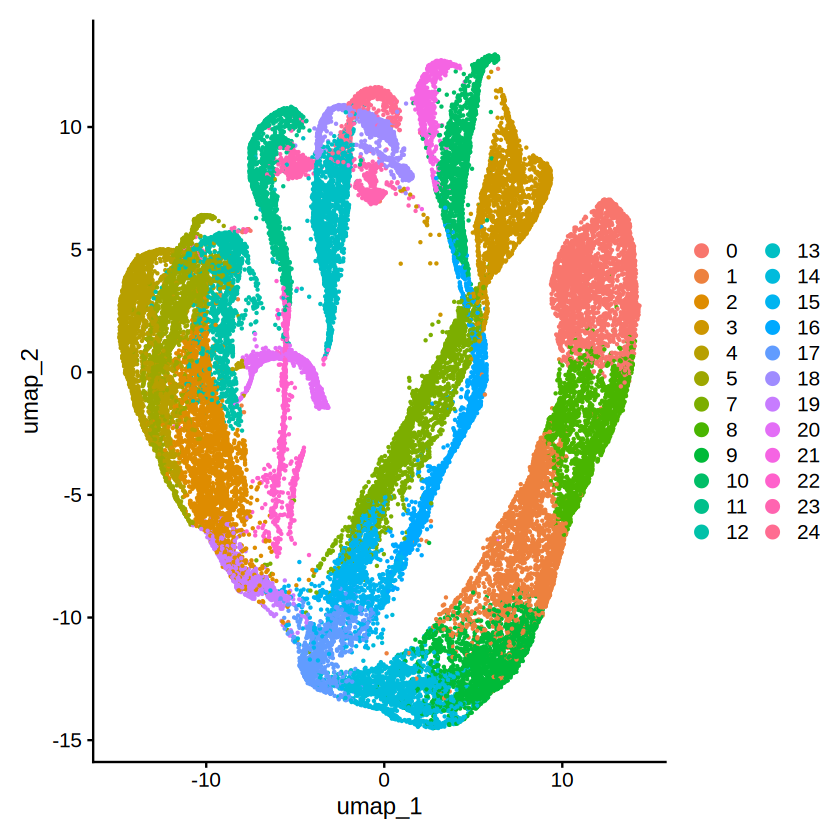

In [23]:
# Check, no suspicious cluster
DimPlot(seu_sub)

In [147]:
table(seu_sub$time.celltype.anno.Li.crude, seu_sub$orig.ident)

                                       
                                        sc_291 sc_292 sc_293 sc_294
  Distal Columella                         252    577    239    662
  Distal Lateral Root Cap                  235    415     82    482
  Elongation_Atrichoblast                  390    266    470    529
  Elongation_Cortex                        575    311    838    610
  Elongation_Endodermis                    571    583    675    711
  Elongation_Pericycle                    1391   1251   1216   1317
  Elongation_Phloem                        230    236    206    223
  Elongation_Procambium                    520    619    534    702
  Elongation_Trichoblast                   370    285    534    507
  Elongation_Xylem                         304    311    316    337
  Maturation_Atrichoblast                  108     42    127    101
  Maturation_Cortex                        213     67    184    143
  Maturation_Endodermis                    358    151    238    179
  Matura

## Muscat

In [24]:
# Read in the gene dictrionary and description
# Don't change anything here
# NOTE: lab cluster path below -- change it to your own path
diction <- read_tsv("/resnick/groups/NolanLab/shared_resources/source_files/features.tsv", col_names=FALSE,  show_col_types = FALSE)
# NOTE: lab cluster path below -- change it to your own path
TF_list <- read_csv("/resnick/groups/NolanLab/shared_resources/source_files/Kay_TF_thalemine_annotations.csv", 
                    col_names = c("gene", "TF_Name", "Description"),
                   show_col_types = FALSE) 

In [144]:
# The muscat fucntion
# This will run muscat DE analysis, perform GO analysis, and then plot heatmaps and DE gene plots
# Don't change anything here
compareDE <- function(obj, 
                      comparison,
                      category, 
                      # reps, 
                      clusters, # which type of subpopulations to test - either cell type or cell/dev
                      p_val_thres=0.05, 
                      FC_thres=1.5,
                      filter_freq=0.1, # freq to filter expression above
                      useDate=T, # if batch/date/rep correction needs to be done then it's TRUE
                      directory = "~/") {
  #  set.seed(19452342)
  
  # subset the object for the days you want to test
  comp <- strsplit(comparison,"-")[[1]]
  obj1 <- subset(obj, cells = colnames(obj)[obj@meta.data[,which(colnames(obj@meta.data)== category)] %in% comp])

  # Here we're using the "edgeR" method in muscat, so the input should be raw counts
  rna.merged <- obj1@assays$RNA@counts
  md <- data.frame(sample_id = factor(obj1$orig.ident),
                   group_id = factor(obj1@meta.data[,which(colnames(obj1@meta.data)==category)]), # which category to test
                   cluster_id = unname(obj1[[clusters]]), # which type of subpopulations to test - either cell type or cell/dev
                   date = factor(obj1$date))
  
  print("finsihed preprocessing")
  
  sce <- SingleCellExperiment(assays = list(counts = rna.merged), colData = md) 
  sce <- prepSCE(sce, kid = "cluster_id", gid = "group_id", sid = "sample_id", drop = FALSE)
  sce <- sce[rowSums(counts(sce) > 1) >= 1, ]
  sce@assays@data$counts <- as.matrix(sce@assays@data$counts)
  
  print("initial SCE formation - done!")
  
  
  pb <- aggregateData(sce, assay = "counts", fun = "sum", by = c("cluster_id", "sample_id"))
  
  print("Agregation - done!")
  
  sample_date <- data.frame("sample_id"=sce$sample_id, 
                            "date"=sce$date)
  sample_date <- unique(sample_date)
  ei <- metadata(sce)$experiment_info
  ei <- left_join(ei, sample_date)
  ei$group_id <- droplevels(ei$group_id)
  ei$date <- droplevels(ei$date)
  if (useDate){ 
    mm <- model.matrix(~ 0 + ei$group_id + ei$date)
    ldate <- length(unique(sample_date$date))
    dimnames(mm) <- list(ei$sample_id, c(levels(ei$group_id), paste0("date",1:(ldate-1))))
  }
  else {
    mm <- model.matrix(~ 0 + ei$group_id)
    dimnames(mm) <- list(ei$sample_id, c(levels(ei$group_id)))
  }
  
  print(mm); print(comparison)
  contrast <- makeContrasts(contrasts = comparison, levels = mm)
  print(contrast)
  # print("hi")
  print("line90")

  # Perform the "edgeR" method in muscat
  # EdgeR gives log2 fold change, ref: https://gist.github.com/jdblischak/11384914#file-rnaseq-de-tutorial-rmd and https://www.biostars.org/p/303806/
  res <- pbDS(pb, design = mm, contrast = contrast, method="edgeR", min_cells=5,filter = "none")
  print("line92")
  
  # comparison <- "day_7-day_9"
  
  labels <- strsplit(comparison,"-")[[1]]
  print("line97")
  res_to_write_frq <- resDS(sce, res, bind = "row", cpm=TRUE, frq=T)
  
  filter_1 <- paste0(labels[1], ".frq", sep="")
  filter_2 <- paste0(labels[2], ".frq", sep="")
  
  all_bg <- filter(res_to_write_frq,
                   get(filter_1) >=filter_freq | get(filter_2) >=filter_freq)
  
  
  diction2<- as.data.frame(diction)
  colnames(diction2)<- c("AGI","gene","non")
  
  
  ##PROBLEM - last sig_DE overwritten
  sig_DE <- left_join(res_to_write_frq, diction2, by=c("gene"="AGI"))
  
  
  
  sig_DE <- sig_DE %>%
    arrange(`p_adj.loc`)
  
  sig_DE <- left_join(sig_DE, TF_list)
  
  sig_DE <- sig_DE %>%
    mutate(up_dn_label = case_when(`logFC` >=log2(1.25) ~ "Up",  
                                   `logFC` <=log2(3/4) ~ "Down",
                                   TRUE ~ "Not DE"))
  
  sig_DE$clust_up_dn <- paste(sig_DE$cluster_id, sig_DE$up_dn_label, sep="_") 
  
  
  sig_DE_fil <- filter(sig_DE, `p_adj.loc`<=p_val_thres & abs(`logFC`) > log2(FC_thres))

  # 20250228 added frequency filter for sig DE 
  # DEGs should be expressed at least frq 0.1 in one group for any comparison
  sig_DE_fil <- filter(sig_DE_fil, 
                       get(filter_1) >=filter_freq | get(filter_2) >=filter_freq)
  
  print("writing")
  base_dir = paste0(directory,comparison,"/")
  dir.create(base_dir,recursive = T)
  write.csv(sig_DE, file = paste(base_dir,"sig_de.csv",sep=""))
  write.csv(sig_DE_fil, file = paste(base_dir,"sig_de_fil.csv",sep=""))
  write.csv(all_bg, file = paste(base_dir,"all_bg.csv",sep=""))
  
  
  # number of DE genes
  
  nb_genes_per_clust <- sig_DE_fil  %>%
    group_by(cluster_id) %>%
    tally()
  
  
  # number of times each gene is DE
  nb_de_gene_count <- sig_DE_fil %>%
    group_by(gene) %>%
    tally(name = "n_clusters_de")
  
  
  nb_p<-ggplot(data=nb_genes_per_clust, aes(x=reorder(cluster_id, -n), y=n)) +
    geom_bar(stat="identity", fill="darkgrey") + ylab("Number of DE genes") + xlab("Subpopulation") + 
    geom_text(aes(label=n), vjust=-0.3, size=4)  + theme_cowplot() + NoLegend() + theme(axis.text.x = element_text(angle = 90, hjust = 0.3, vjust = 1))
  
  # get number of times a gene is DE across the number of clusters
  gene_de_n <- nb_de_gene_count %>%
    group_by(n_clusters_de) %>%
    tally()
  
  gene_de_n$highlight <- c("yes", rep("no", (nrow(gene_de_n)-1)))
  
  total_de_gene_number <- length(unique(sig_DE_fil$gene))
  
  total_de_gene_number_label <- paste(length(unique(sig_DE_fil$gene)), "\n Total DE genes", sep = " ")
  
  
  
  nb_gene_p2<-ggplot(data=gene_de_n, aes(x=reorder(n_clusters_de, -n), y=n, fill=highlight)) +
    geom_bar(stat="identity") + 
    ylab("Number of genes") + 
    xlab("Number of Subpopulations Differentially Expressed") + 
    geom_text(aes(label=n), vjust=-0.3, size=4) + 
    annotate("text", x = 9, y=total_de_gene_number-(total_de_gene_number/1.2), label=total_de_gene_number_label, size=6) + 
    scale_fill_manual(values = c("darkgrey", "red")) + 
    theme(legend.position = "none")
  
  
  nb_gene_p2 <- nb_gene_p2 + theme_cowplot() + NoLegend()
  num_de_bar <- nb_gene_p2 / nb_p
  ggsave(paste(base_dir,"DE_genes_plot.pdf",sep=""),num_de_bar, width=24, height=15)
  
  
  ##PROBLEM: what are the nb_total_names?
  # volcano plots
  
  # need combo of cluster and gene 
  nb_de_total_names <- sig_DE
  nb_DE_sig <- sig_DE_fil
  
  nb_de_total_names$sig <- nb_de_total_names$gene %in% nb_DE_sig$gene
  
  #nb_de_total_names$known_drought <- nb_de_total_names$gene_id %in% drought_names$gene_id
  
  # nb_de_total_names %>%
  #   group_by(gene_id) %>%
  #   filter(known_drought==T & sig==T) %>%
  #   ungroup() %>%
  #   select(gene_id) %>%
  #   distinct()
  
  nb_de_total_names <- dplyr::rename(nb_de_total_names, log2FC=logFC)
  
  nb_de_total_names$logFDR <- -log10(nb_de_total_names$p_adj.loc)
  # color up/down and facet plot 
  
  # filter(nb_de_total, p_val_adj<=0.05) %>%
  # filter(avg_logFC>=log2(1.25) | avg_logFC<=log2(3/4))

  # 20250228: added p-value threshold for DE genes labelled on the volcano plot
  all_time_pts <- nb_de_total_names %>%
    mutate(up_dn_label = case_when(log2FC >=log2(1.25) & p_adj.loc<=p_val_thres ~ "Up",  
                                   log2FC <=log2(3/4) & p_adj.loc<=p_val_thres ~ "Down",
                                   TRUE ~ "Not DE"))
  all_time_pts$up_dn_label <- factor(all_time_pts$up_dn_label, levels=c("Up", "Down", "Not DE"))
  
  
  all_time_pts$sig <- all_time_pts$up_dn_label !="Not DE"
  # set limits of FC and logFDR
  all_time_pts_cut <- all_time_pts
  # round to cutoff at 4
  all_time_pts_cut$logFDR[all_time_pts_cut$logFDR>10] <- 10
  
  # limit log2FC to 4 
  all_time_pts_cut$log2FC[all_time_pts_cut$log2FC>10] <- 10
  all_time_pts_cut$log2FC[all_time_pts_cut$log2FC < -10] <- -10
  
  # # labels 
  # 
  # time.labs <- c("15 min", "30 min", "1 hour", "2 hour", "4 hour", "8 hour")
  # names(time.labs) <- c(1, 2, 3, 4, 5, 6)
  
  genes_w_names <- filter(all_time_pts_cut, !grepl("^AT[1-5]", gene) & sig==TRUE)
  
  top_genes_to_label <- genes_w_names %>%
    group_by(cluster_id) %>%
    top_n(10, logFDR) %>%
    top_n(2, log2FC)
  top_genes_to_label2 <- genes_w_names %>%
    group_by(cluster_id) %>%
    top_n(10, logFDR) %>%
    top_n(2, -log2FC)
  
  top_genes_to_label3 <- genes_w_names %>%
    group_by(cluster_id) %>%
    top_n(2, log2FC)
  top_genes_to_label4 <- genes_w_names %>%
    group_by(cluster_id) %>%
    top_n(2, -log2FC)
  
  
  # top_genes_to_label5 <- genes_w_names %>%
  #   group_by(cluster) %>%
  #   filter(known_drought==T) %>%
  #   top_n(100, logFDR) %>%
  #   top_n(2, log2FC)
  # top_genes_to_label6 <- genes_w_names %>%
  #   group_by(cluster) %>%
  #   filter(known_drought==T) %>%
  #   top_n(100, logFDR) %>%
  #   top_n(2, -log2FC)
  # top_genes_to_label7 <- genes_w_names %>%
  #   group_by(cluster) %>%
  #   filter(known_drought==T) %>%
  #   top_n(2, log2FC)
  # top_genes_to_label8 <- genes_w_names %>%
  #   group_by(cluster) %>%
  #   filter(known_drought==T) %>%
  #   top_n(2, -log2FC)
  
  # top_genes_to_label <- bind_rows(top_genes_to_label, top_genes_to_label2, top_genes_to_label3, top_genes_to_label4, top_genes_to_label5, top_genes_to_label6, top_genes_to_label7, top_genes_to_label8) %>%
  #   distinct()
  
  top_genes_to_label <- bind_rows(top_genes_to_label, top_genes_to_label2, top_genes_to_label3, top_genes_to_label4) %>%
    distinct()
  
  up_genes_to_label <- filter(top_genes_to_label, log2FC>0)
  down_genes_to_label <- filter(top_genes_to_label, log2FC<0)
  
  
  p = ggplot(all_time_pts_cut, aes(log2FC, logFDR)) +
    geom_point(aes(col=up_dn_label), alpha = 0.4) +
    scale_color_manual(values=c("red", "blue", "black")) + 
    scale_x_continuous(limits=c(-12, 12), breaks = c(-10, -8, -6, -4, -2, 0, 2, 4, 6, 8, 10)) + scale_y_continuous(limits=c(0, 11), breaks = c(0, 2, 4, 6, 8, 10)) + 
    xlab(expression(Average~log[2]~fold~change)) + 
    ylab(expression(-log[10]~adjusted~P~value)) + 
    scale_alpha(guide="none")
  
  all_plot <- p+ geom_label_repel(data=up_genes_to_label, 
                                  aes(label=gene), 
                                  size = 4, 
                                  nudge_x = 11.5, 
                                  direction = "y", 
                                  alpha = 0.7, box.padding = 0.5) + 
    geom_label_repel(data=down_genes_to_label, 
                     aes(label=gene), 
                     size = 4, 
                     nudge_x = -11.5, 
                     direction = "y", 
                     alpha = 0.7, box.padding = 0.5) +
    labs(color = "Regulation") + ggtitle("") + theme_minimal() + theme(plot.title = element_text(hjust = 0.5))
  
  
  
  all_plot + facet_wrap(~ cluster_id, nrow = 4) + ggtitle("DE genes by cell type") + theme_cowplot()
  
  ggsave(paste(base_dir,"Volcano_plot.pdf",sep=""), all_plot,width=24, height=15)
  
  
  
  # Overlap and GO for all genes 
  
  options(repr.plot.width = 14, repr.plot.height = 12)
  
  markers_sel <- select(sig_DE_fil, gene, cluster_id)
  
  markers_list <- split(markers_sel, f=markers_sel$cluster_id)
  
  #this makes list from long df of gene lists - TARGET is what we want to keep
  markers_list  <- lapply(markers_list, function(x) x[names(x)=="gene"])
  # convert each sublist into character and eliminate duplicates
  markers_list  <- lapply(markers_list, function(x) as.character(unique(x$gene)))
  
  ## GeneOverlap 
  
  # nfeatures RNA
  
  genome_size <- length(unique(all_bg$gene))
  
  #compare all lists
  gom.self <- newGOM(markers_list, markers_list, genome.size=genome_size)
  
  
  int <- getNestedList(gom.self, "intersection")
  int_matrix <- getMatrix(gom.self, "intersection")
  p.val <- getMatrix(gom.self, "pval")
  JC <- getMatrix(gom.self, "Jaccard")
  
  # log of p.val for intersection
  p.val_log <- -log10(p.val + 1e-200)
  
  tryCatch (
    {
      olap <- Heatmap(p.val_log, name = "-log10_pval", col = colorRamp2(c(0, 200), c("beige", "red")), 
                      column_title = "Number of shared DS genes among cell types", cluster_rows = T,cluster_columns = T, 
                      use_raster= FALSE, show_column_names = TRUE, show_row_names = TRUE, show_row_dend = TRUE, show_column_dend = TRUE, 
                      cell_fun = function(j, i, x, y, width, height, fill) {grid.text(sprintf("%.0f", int_matrix[i, j]), x, y, gp = gpar(fontsize = 10))
                      }) 
      
      # padding - bottom, left, top, right
      
      pdf(file=paste(base_dir,"Overlap.pdf",sep=""), width=18, height=16)
      
      draw(olap, padding = unit(c(5, 5, 5, 10), "mm"), heatmap_legend_side = "left")
      
      dev.off()
    }, error = function(cond) {
      message(paste("URL does not seem to exist:", "url"))
      message("Here's the original error message:")
      message(conditionMessage(cond))
      # Choose a return value in case of error
      NA}, 
    warning = function(cond) {
      message(paste("URL caused a warning:", "url"))
      message("Here's the original warning message:")
      message(conditionMessage(cond))
      # Choose a return value in case of warning
      NULL
    },finally = message("bye")
  )
  
  print("line376")
  
  cluster_GO <- gost(markers_list, organism = "athaliana", correction_method = "fdr", significant = F, multi_query = F)
  
  cluster_GO_df <- cluster_GO[[1]]
  
  cluster_GO_sig <- filter(cluster_GO_df, p_value<=0.01)
  
  # top  terms for each cluster
  
  cluster_GO_sig %>%
    filter(source=="GO:BP", intersection_size>=5) %>%
    group_by(query) %>%
    top_n(15, wt = -p_value) %>%
    arrange(desc(p_value)) -> top_GO
  
  GO_n <- cluster_GO_sig %>%
    filter(source=="GO:BP", intersection_size>=5) %>%
    group_by(term_id) %>%
    tally() %>%
    arrange(desc(n))
  
  
  GO_n <- dplyr::rename(GO_n, "n_clusters"=n)
  
  cluster_GO_sig_n <- left_join(cluster_GO_sig, GO_n)
  
  # get all terms for the top ones so that all clusters have values
  
  top_GO_all <- filter(cluster_GO_df, term_id %in% top_GO$term_id)
  
  
  #spread and plot
  print("line409")
  tryCatch({
    top_GO_sel <- select(top_GO_all, query, p_value, term_id, term_name)
    
    spread_GO <- spread(top_GO_sel, key = query, p_value)
    
    spread_GO[is.na(spread_GO)] <- 1
    
    spread_GO_m <- as.matrix(-log10(spread_GO[3:ncol(spread_GO)]))
    rownames(spread_GO_m) <- spread_GO$term_name
    print("line419")
    print(spread_GO_m)
    GO_hm <- Heatmap(spread_GO_m, name = "-log10_pval", 
                     heatmap_legend_param = list(title_position="topcenter", color_bar = "continuous"), col = colorRamp2(c(0, 20), c("beige", "#e31a1c")), 
                     cluster_rows = T,cluster_columns = T, 
                     clustering_distance_rows = "pearson", clustering_distance_columns = "pearson",
                     use_raster= FALSE, show_column_names = TRUE, show_row_names = TRUE, show_row_dend = TRUE, show_column_dend = TRUE, 
                     row_names_gp = gpar(fontsize = 14), 
                     column_names_gp = gpar(fontsize = 14)) 
  },error = function(cond) NA, warning = function(cond) NULL,finally = {NULL})
  print("line427")
  # padding - bottom, left, top, right
  tryCatch(
    {
      pdf(file=paste(base_dir,"GO_hm.pdf",sep=""), width=20, height=16)
      draw(GO_hm, padding = unit(c(60, 15, 5, 80), "mm"), heatmap_legend_side = "left")
      dev.off()
    },error = function(cond) NA, warning = function(cond) NULL,finally = {NULL}
  )
  
  ### Up vs down overlap and GO ###
  
  markers_sel <- select(sig_DE_fil, gene, clust_up_dn)
  
  markers_list <- split(markers_sel, f=markers_sel$clust_up_dn)
  
  #this makes list from long df of gene lists - TARGET is what we want to keep
  markers_list  <- lapply(markers_list, function(x) x[names(x)=="gene"])
  # convert each sublist into character and eliminate duplicates
  markers_list  <- lapply(markers_list, function(x) as.character(unique(x$gene)))
  
  ## GeneOverlap 
  
  
  
  #compare all lists
  gom.self <- newGOM(markers_list, markers_list, genome.size=genome_size)
  print("line454")
  
  int <- getNestedList(gom.self, "intersection")
  int_matrix <- getMatrix(gom.self, "intersection")
  p.val <- getMatrix(gom.self, "pval")
  JC <- getMatrix(gom.self, "Jaccard")
  
  # log of p.val for intersection
  p.val_log <- -log10(p.val + 1e-200)
  
  tryCatch( {
    olap <- Heatmap(p.val_log, name = "-log10_pval", col = colorRamp2(c(0, 200), c("beige", "red")), 
                    column_title = "Number of shared DS genes among cell types - BL", cluster_rows = T,cluster_columns = T, use_raster= FALSE, show_column_names = TRUE, show_row_names = TRUE, show_row_dend = TRUE, show_column_dend = TRUE, cell_fun = function(j, i, x, y, width, height, fill) {grid.text(sprintf("%.0f", int_matrix[i, j]), x, y, gp = gpar(fontsize = 10))
                    }) 
    
    pdf(file=paste(base_dir,"Overlap_up_vs_down.pdf",sep=""), width=18, height=15)
    
    
    # padding - bottom, left, top, right
    draw(olap, padding = unit(c(5, 5, 5, 10), "mm"), heatmap_legend_side = "left")
    
    
    dev.off() }
    
    ,error = function(cond) {
      message(paste("URL does not seem to exist:", "url"))
      message("Here's the original error message:")
      message(conditionMessage(cond))
      # Choose a return value in case of error
      NA}, 
    warning = function(cond) {
      message(paste("URL caused a warning:", "url"))
      message("Here's the original warning message:")
      message(conditionMessage(cond))
      # Choose a return value in case of warning
      NULL
    },finally = message("bye")
  )
  
  print("line493")
  # GO 
  tryCatch({
    cluster_GO <- gost(markers_list, organism = "athaliana", correction_method = "fdr", significant = F, multi_query = F)
    
    cluster_GO_df <- cluster_GO[[1]]
    
    cluster_GO_sig <- filter(cluster_GO_df, p_value<=0.01)
    
    # top  terms for each cluster
    
    cluster_GO_sig %>%
      filter(source=="GO:BP", intersection_size>=8) %>%
      group_by(query) %>%
      top_n(5, wt = -p_value) %>%
      arrange(desc(p_value)) -> top_GO
    
    GO_n <- cluster_GO_sig %>%
      filter(source=="GO:BP", intersection_size>=8) %>%
      group_by(term_id) %>%
      tally() %>%
      arrange(desc(n))
    
    
    GO_n <- dplyr::rename(GO_n, "n_clusters"=n)
    
    cluster_GO_sig_n <- left_join(cluster_GO_sig, GO_n)
    
    # get all terms for the top ones so that all clusters have values
    
    top_GO_all <- filter(cluster_GO_df, term_id %in% top_GO$term_id)
    
    
    #spread and plot
    
    
    top_GO_sel <- select(top_GO_all, query, p_value, term_id, term_name)
    
    spread_GO <- spread(top_GO_sel, key = query, p_value)
    
    spread_GO[is.na(spread_GO)] <- 1
    
    spread_GO_m <- as.matrix(-log10(spread_GO[3:ncol(spread_GO)]))
    rownames(spread_GO_m) <- spread_GO$term_name
  },error = function(cond) {
    message(paste("URL does not seem to exist:", "url"))
    message("Here's the original error message:")
    message(conditionMessage(cond))
    # Choose a return value in case of error
    NA}, 
  warning = function(cond) {
    message(paste("URL caused a warning:", "url"))
    message("Here's the original warning message:")
    message(conditionMessage(cond))
    # Choose a return value in case of warning
    NULL
  },finally = message("bye"))
  print("line537")
  tryCatch({
    GO_hm <- Heatmap(spread_GO_m, 
                     name = "-log10_pval", 
                     heatmap_legend_param = list(title_position="topcenter", color_bar = "continuous"), 
                     col = colorRamp2(c(0, 10), c("beige", "#e31a1c")), 
                     cluster_rows = T, 
                     cluster_columns = T, 
                     use_raster= FALSE, 
                     show_column_names = TRUE, 
                     show_row_names = TRUE, 
                     show_row_dend = TRUE, 
                     show_column_dend = TRUE,
                     clustering_distance_columns = "pearson", 
                     clustering_distance_rows = "pearson",
                     row_names_gp = gpar(fontsize = 14), 
                     column_names_gp = gpar(fontsize = 14)) 
    
    pdf(file=paste(base_dir,"Up_vs_Down_GO_hm.pdf",sep=""), width=20, height=16)
    
    draw(GO_hm, padding = unit(c(100, 30, 5, 100), "mm"), heatmap_legend_side = "left")
    
    dev.off()
  },error=function(cond) {print("pass"); NA})
  
  print(paste("finished DE for ", comparison))
  
  # write the session info to text so we have a record of which version was used
  
  writeLines(capture.output(sessionInfo()), paste(base_dir,"sessionInfo.txt",sep=""))
  
  
}


In [26]:
# Read in the GO info
# Don't change anything here
GOcats <- read.csv(file.path(Sys.getenv("FERONIA_REPO", "."), "scripts_and_inputs/Analysis/Differential_expression_analysis/inputs/athaliana.GO_BP.ENSG.gmt"),header = F,sep = '\t')

In [28]:
head(seu_sub, 3)

,orig.ident,nCount_RNA,nFeature_RNA,nCount_spliced_RNA,nFeature_spliced_RNA,nCount_unspliced_RNA,nFeature_unspliced_RNA,percent.mt,percent.cp,nCount_SCT,⋯,pANN_0.25_0.15_526,DF.classifications_0.25_0.15_526,pANN_0.25_0.15_726,DF.classifications_0.25_0.15_726,integrated_snn_res.0.5,time.anno.Li,celltype.anno.Li,genotype,geno,date
,<chr>,<dbl>,<int>,<dbl>,<int>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<chr>,<dbl>,<chr>,<fct>,<chr>,<fct>,<fct>,<chr>,<chr>
AAACCCAAGGACTTCT_4,sc_291,2801,1473,2678,1418,123,91,0.07140307,0.1071046,7949,⋯,NA,NA,NA,NA,4,Elongation,Procambium,WT,WT,1
AAACCCAAGGTCGTGA_4,sc_291,14092,3995,13277,3834,815,453,0.26256032,0.3690037,9904,⋯,NA,NA,NA,NA,3,Transition Domain,Trichoblast,WT,WT,1
AAACCCAAGTGCACTT_4,sc_291,4888,2274,4596,2200,292,183,0.22504092,0.3273322,8348,⋯,NA,NA,NA,NA,7,Transition Domain,Trichoblast,WT,WT,1


In [29]:
# Specify the conditions to be compared
# Format: condition_1-condition_2 (note that there shouldn't be any spaces in between)
# mutant - control or treated - control
# Change this to fit your data
my_comparisons <- c("fer_4-WT")

In [31]:
# Copy an obj named tc
tc <- seu_sub

In [35]:
unique(tc$geno)

[1] "WT"    "fer-4"

In [36]:
# This is optional. Change this to fit your data if needed. If not, you can comment this block out
# This is to simplify the group column, because no space is allowed in the group column
tc$group_clean <- case_when(
    tc$geno == "WT" ~ "WT",
    tc$geno == "fer-4" ~ "fer_4")

In [37]:
unique(tc$group_clean)

[1] "WT"    "fer_4"

### Cluster cells based on time.celltype.anno.Li

In [145]:
table(tc$time.celltype.anno.Li)


                                Distal Columella 
                                            1730 
                         Distal Lateral Root Cap 
                                            1215 
                         Elongation_Atrichoblast 
                                            1655 
                               Elongation_Cortex 
                                            2334 
                           Elongation_Endodermis 
                                            2540 
          Elongation_Metaphloem & Companion Cell 
                                             605 
                            Elongation_Metaxylem 
                                             638 
                Elongation_Phloem Pole Pericycle 
                                            1247 
                           Elongation_Procambium 
                                            2383 
                          Elongation_Protophloem 
                                             287 

In [146]:
# Run compareDE() through all comparisons
# This will output results in the directory you specified. Change the directory to your project folder
# Change category, clusters and useDate to fit your samples
for (i in 1:length(my_comparisons)) {
  this_comparison <- my_comparisons[i]
  print(this_comparison)
  
    compareDE(obj = tc, 
            comparison = this_comparison, 
            category="group_clean", # the column that matches the items in my_comparisons
            clusters = "time.celltype.anno.Li", # how you want the cells to be clustered for DE analysis
            useDate = TRUE, # if batch/date/rep correction needs to be done then it's TRUE
            # NOTE: lab cluster path below -- change it to your own path
            directory = "/resnick/groups/NolanLab/cchen/Feronia/analysis/muscat_result/20260317_salinity_timecourse_useDateT_noSuspiciousClusters/group_timecelltypeannoLi/" # your dir
  ) }

[1] "fer_4-WT"
[1] "finsihed preprocessing"


Warning message in asMethod(object):
“sparse->dense coercion: allocating vector of size 7.5 GiB”


[1] "initial SCE formation - done!"
[1] "Agregation - done!"


Joining with `by = join_by(sample_id)`


       fer_4 WT date1
sc_291     0  1     0
sc_292     1  0     0
sc_293     0  1     1
sc_294     1  0     1
attr(,"assign")
[1] 1 1 2
attr(,"contrasts")
attr(,"contrasts")$`ei$group_id`
[1] "contr.treatment"

attr(,"contrasts")$`ei$date`
[1] "contr.treatment"

[1] "fer_4-WT"
       Contrasts
Levels  fer_4-WT
  fer_4        1
  WT          -1
  date1        0
[1] "line90"
  |======================================================================| 100%

[1] "line92"
[1] "line97"


...

[1] "line409"
[1] "line419"
                                                Distal Columella
response to acid chemical                             4.84927212
response to hypoxia                                   2.38036690
defense response to insect                            1.91761081
organic acid metabolic process                        2.75030244
water transport                                      12.12843508
response to stress                                   12.00525846
response to oxidative stress                         10.77694206
cell-cell junction assembly                           0.72266985
metabolic process                                     0.09828792
nucleotide-sugar metabolic process                    1.56962567
nucleotide-sugar biosynthetic process                 1.81718910
response to temperature stimulus                      1.17251038
response to heat                                      1.04159012
response to water deprivation                         5.463706

bye



[1] "line493"


Joining with `by = join_by(term_id)`
bye



[1] "line537"
[1] "finished DE for  fer_4-WT"


### Cluster cells based on dev time only

In [40]:
# Get dev time from time.celltype.anno.Li
tc$time.anno.Li <- str_split_fixed(tc$time.celltype.anno.Li, pattern = "_", n = 2)[ , 1]

In [41]:
table(tc$time.anno.Li)


         Distal Columella   Distal Lateral Root Cap                Elongation 
                     1730                      1215                     17907 
               Maturation      Proliferation Domain        Proximal Columella 
                     3573                      4281                       569 
Proximal Lateral Root Cap         Transition Domain 
                     8933                      6456 

In [42]:
table(tc$group_clean)


fer_4    WT 
23009 21655 

In [43]:
# Run compareDE() through all comparisons
# This will output results in the directory you specified. Change the directory to your project folder
# Change category, clusters and useDate to fit your samples
for (i in 1:length(my_comparisons)) {
  this_comparison <- my_comparisons[i]
  print(this_comparison)
  
    compareDE(obj = tc, 
            comparison = this_comparison, 
            category="group_clean", # the column that matches the items in my_comparisons
            clusters = "time.anno.Li", # how you want the cells to be clustered for DE analysis
            useDate = TRUE, # if batch/date/rep correction needs to be done then it's TRUE
            # NOTE: lab cluster path below -- change it to your own path
            directory = "/resnick/groups/NolanLab/cchen/Feronia/analysis/muscat_result/20260317_salinity_timecourse_useDateT_noSuspiciousClusters/group_timeannoLi/" # your dir
  ) }

[1] "fer_4-WT"
[1] "finsihed preprocessing"


Warning message in asMethod(object):
“sparse->dense coercion: allocating vector of size 7.5 GiB”


[1] "initial SCE formation - done!"
[1] "Agregation - done!"


Joining with `by = join_by(sample_id)`


       fer_4 WT date1
sc_291     0  1     0
sc_292     1  0     0
sc_293     0  1     1
sc_294     1  0     1
attr(,"assign")
[1] 1 1 2
attr(,"contrasts")
attr(,"contrasts")$`ei$group_id`
[1] "contr.treatment"

attr(,"contrasts")$`ei$date`
[1] "contr.treatment"

[1] "fer_4-WT"
       Contrasts
Levels  fer_4-WT
  fer_4        1
  WT          -1
  date1        0
[1] "line90"
  |======================================================================| 100%

[1] "line92"
[1] "line97"


...

[1] "line409"
[1] "line419"
                                              Distal Columella
response to acid chemical                            4.8492721
response to hypoxia                                  2.3803669
defense response to insect                           1.9176108
translation                                          0.0000000
water transport                                     12.1284351
response to stress                                  12.0052585
response to oxidative stress                        10.7769421
response to water deprivation                        5.4637067
response to water                                    5.2950711
response to external stimulus                        1.6530381
response to biotic stimulus                          2.1108128
response to abiotic stimulus                        10.7117300
response to toxic substance                          8.4076692
response to endogenous stimulus                      8.4918484
response to hormone        

bye



[1] "line493"


Joining with `by = join_by(term_id)`
bye



[1] "line537"
[1] "finished DE for  fer_4-WT"


### Cluster cells based on cell type only

In [45]:
table(tc$celltype.anno.Li)


           Quiescent Center                   Columella 
                         25                        2299 
           Lateral Root Cap                Atrichoblast 
                      10148                        5203 
                Trichoblast                      Cortex 
                       6937                        4113 
                 Endodermis Metaphloem & Companion Cell 
                       4050                         990 
                Protophloem                  Procambium 
                        317                        2846 
       Xylem Pole Pericycle       Phloem Pole Pericycle 
                       4737                        1299 
                 Protoxylem                   Metaxylem 
                        956                         744 

In [46]:
table(tc$group_clean)


fer_4    WT 
23009 21655 

In [47]:
# Run compareDE() through all comparisons
# This will output results in the directory you specified. Change the directory to your project folder
# Change category, clusters and useDate to fit your samples
for (i in 1:length(my_comparisons)) {
  this_comparison <- my_comparisons[i]
  print(this_comparison)
  
    compareDE(obj = tc, 
            comparison = this_comparison, 
            category="group_clean", # the column that matches the items in my_comparisons
            clusters = "celltype.anno.Li", # how you want the cells to be clustered for DE analysis
            useDate = TRUE, # if batch/date/rep correction needs to be done then it's TRUE
            # NOTE: lab cluster path below -- change it to your own path
            directory = "/resnick/groups/NolanLab/cchen/Feronia/analysis/muscat_result/20260317_salinity_timecourse_useDateT_noSuspiciousClusters/group_celltypeannoLi/" # your dir
  ) }

[1] "fer_4-WT"
[1] "finsihed preprocessing"


Warning message in asMethod(object):
“sparse->dense coercion: allocating vector of size 7.5 GiB”


[1] "initial SCE formation - done!"
[1] "Agregation - done!"


Joining with `by = join_by(sample_id)`


       fer_4 WT date1
sc_291     0  1     0
sc_292     1  0     0
sc_293     0  1     1
sc_294     1  0     1
attr(,"assign")
[1] 1 1 2
attr(,"contrasts")
attr(,"contrasts")$`ei$group_id`
[1] "contr.treatment"

attr(,"contrasts")$`ei$date`
[1] "contr.treatment"

[1] "fer_4-WT"
       Contrasts
Levels  fer_4-WT
  fer_4        1
  WT          -1
  date1        0
[1] "line90"
  |======================================================================| 100%

[1] "line92"
[1] "line97"


...

[1] "line409"
[1] "line419"
                                                                          Atrichoblast
response to acid chemical                                                  0.286803911
response to hypoxia                                                        1.354530244
carbohydrate metabolic process                                             1.426163036
organic acid metabolic process                                             0.927329574
rRNA processing                                                            0.821485831
translation                                                                0.021676902
sulfur compound metabolic process                                          0.218127217
water transport                                                            0.803328588
response to stress                                                         3.865919120
response to oxidative stress                                               3.716329707
lipid biosynthe

bye



[1] "line493"


Joining with `by = join_by(term_id)`
bye



[1] "line537"
[1] "finished DE for  fer_4-WT"


## Plot Feronia paper figures

### DE analysis

In [86]:
# Read in results
# NOTE: lab cluster path below -- change it to your own path
sig_DE_fil <- read.delim("/resnick/groups/NolanLab/cchen/Feronia/analysis/muscat_result/20260317_salinity_timecourse_useDateT_noSuspiciousClusters/group_timecelltypeannoLi/fer_4-WT/sig_de_fil.csv",
                        sep = ",", header = T)

head(sig_DE_fil)

,X,gene,cluster_id,sc_292.cpm,sc_294.cpm,sc_291.cpm,sc_293.cpm,sc_292.frq,sc_294.frq,sc_291.frq,⋯,p_val,p_adj.loc,p_adj.glb,contrast,gene.y,non,TF_Name,Description,up_dn_label,clust_up_dn
,<int>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
1,1,AT3G51550,Elongation_Cortex,0.165,0.362,288.0,323.0,0.00322,0.00164,0.830,⋯,4.05e-230,8.44e-226,2.91e-224,fer_4-WT,FER,Gene Expression,NA,NA,Down,Elongation_Cortex_Down
2,2,AT3G51550,Elongation_Phloem Pole Pericycle,0.000,0.267,173.0,169.0,0.00000,0.00305,0.711,⋯,7.28e-190,1.51e-185,2.62e-184,fer_4-WT,FER,Gene Expression,NA,NA,Down,Elongation_Phloem Pole Pericycle_Down
3,3,AT3G51550,Elongation_Trichoblast,0.000,1.690,228.0,297.0,0.00000,0.01380,0.916,⋯,6.68e-177,1.40e-172,1.60e-171,fer_4-WT,FER,Gene Expression,NA,NA,Down,Elongation_Trichoblast_Down
4,4,AT3G51550,Proliferation Domain_Trichoblast,0.000,0.669,80.2,71.9,0.00000,0.00439,0.604,⋯,7.70e-170,1.57e-165,1.38e-164,fer_4-WT,FER,Gene Expression,NA,NA,Down,Proliferation Domain_Trichoblast_Down
5,5,AT3G51550,Elongation_Endodermis,0.000,0.111,240.0,252.0,0.00000,0.00141,0.816,⋯,3.08e-151,6.51e-147,4.43e-146,fer_4-WT,FER,Gene Expression,NA,NA,Down,Elongation_Endodermis_Down
6,6,AT3G59370,Elongation_Phloem Pole Pericycle,1090.000,2160.000,5390.0,4820.0,0.76200,0.69800,0.903,⋯,2.70e-135,2.79e-131,3.23e-130,fer_4-WT,AT3G59370,Gene Expression,NA,NA,Down,Elongation_Phloem Pole Pericycle_Down


In [87]:
# Parameters used in the function
p_val_thres=0.05 
FC_thres=1.5
filter_freq=0.1 # freq to filter expression above

In [88]:
# Filter 
sig_DE_fil <- sig_DE_fil %>%
   filter(`p_adj.loc`<=p_val_thres & abs(`logFC`) > log2(FC_thres))

In [89]:
cluster_id = "time.celltype.anno.Li"

In [90]:
# number of DE genes
nb_genes_per_clust <- sig_DE_fil  %>%
  group_by(cluster_id, up_dn_label) %>%
  tally()

# number of times each gene is DE
nb_de_gene_count <- sig_DE_fil %>%
  group_by(gene, up_dn_label) %>%
  tally(name = "n_clusters_de")


In [91]:
head(nb_genes_per_clust, 3)

cluster_id,up_dn_label,n
<chr>,<chr>,<int>
Distal Columella,Down,213
Distal Columella,Up,159
Distal Lateral Root Cap,Down,95


In [92]:
# Compute totals per cluster
nb_totals <- nb_genes_per_clust %>%
  group_by(cluster_id) %>%
  summarise(total_n = sum(n), .groups = "drop")

# Merge totals back into data
nb_genes_per_clust2 <- nb_genes_per_clust %>%
  left_join(nb_totals, by = "cluster_id") %>%
  # reorder factor: descending total_n
  mutate(cluster_id = fct_reorder(cluster_id, -total_n))

# Reorder by descending total
nb_genes_per_clust2 <- nb_genes_per_clust2 %>%
  mutate(cluster_id = fct_reorder(cluster_id, total_n, .desc = TRUE))


In [93]:
unique(nb_genes_per_clust2$up_dn_label )

[1] "Down" "Up"

In [94]:
nb_genes_per_clust2$up_dn_label <- factor(nb_genes_per_clust2$up_dn_label, levels = c("Up", "Down"))

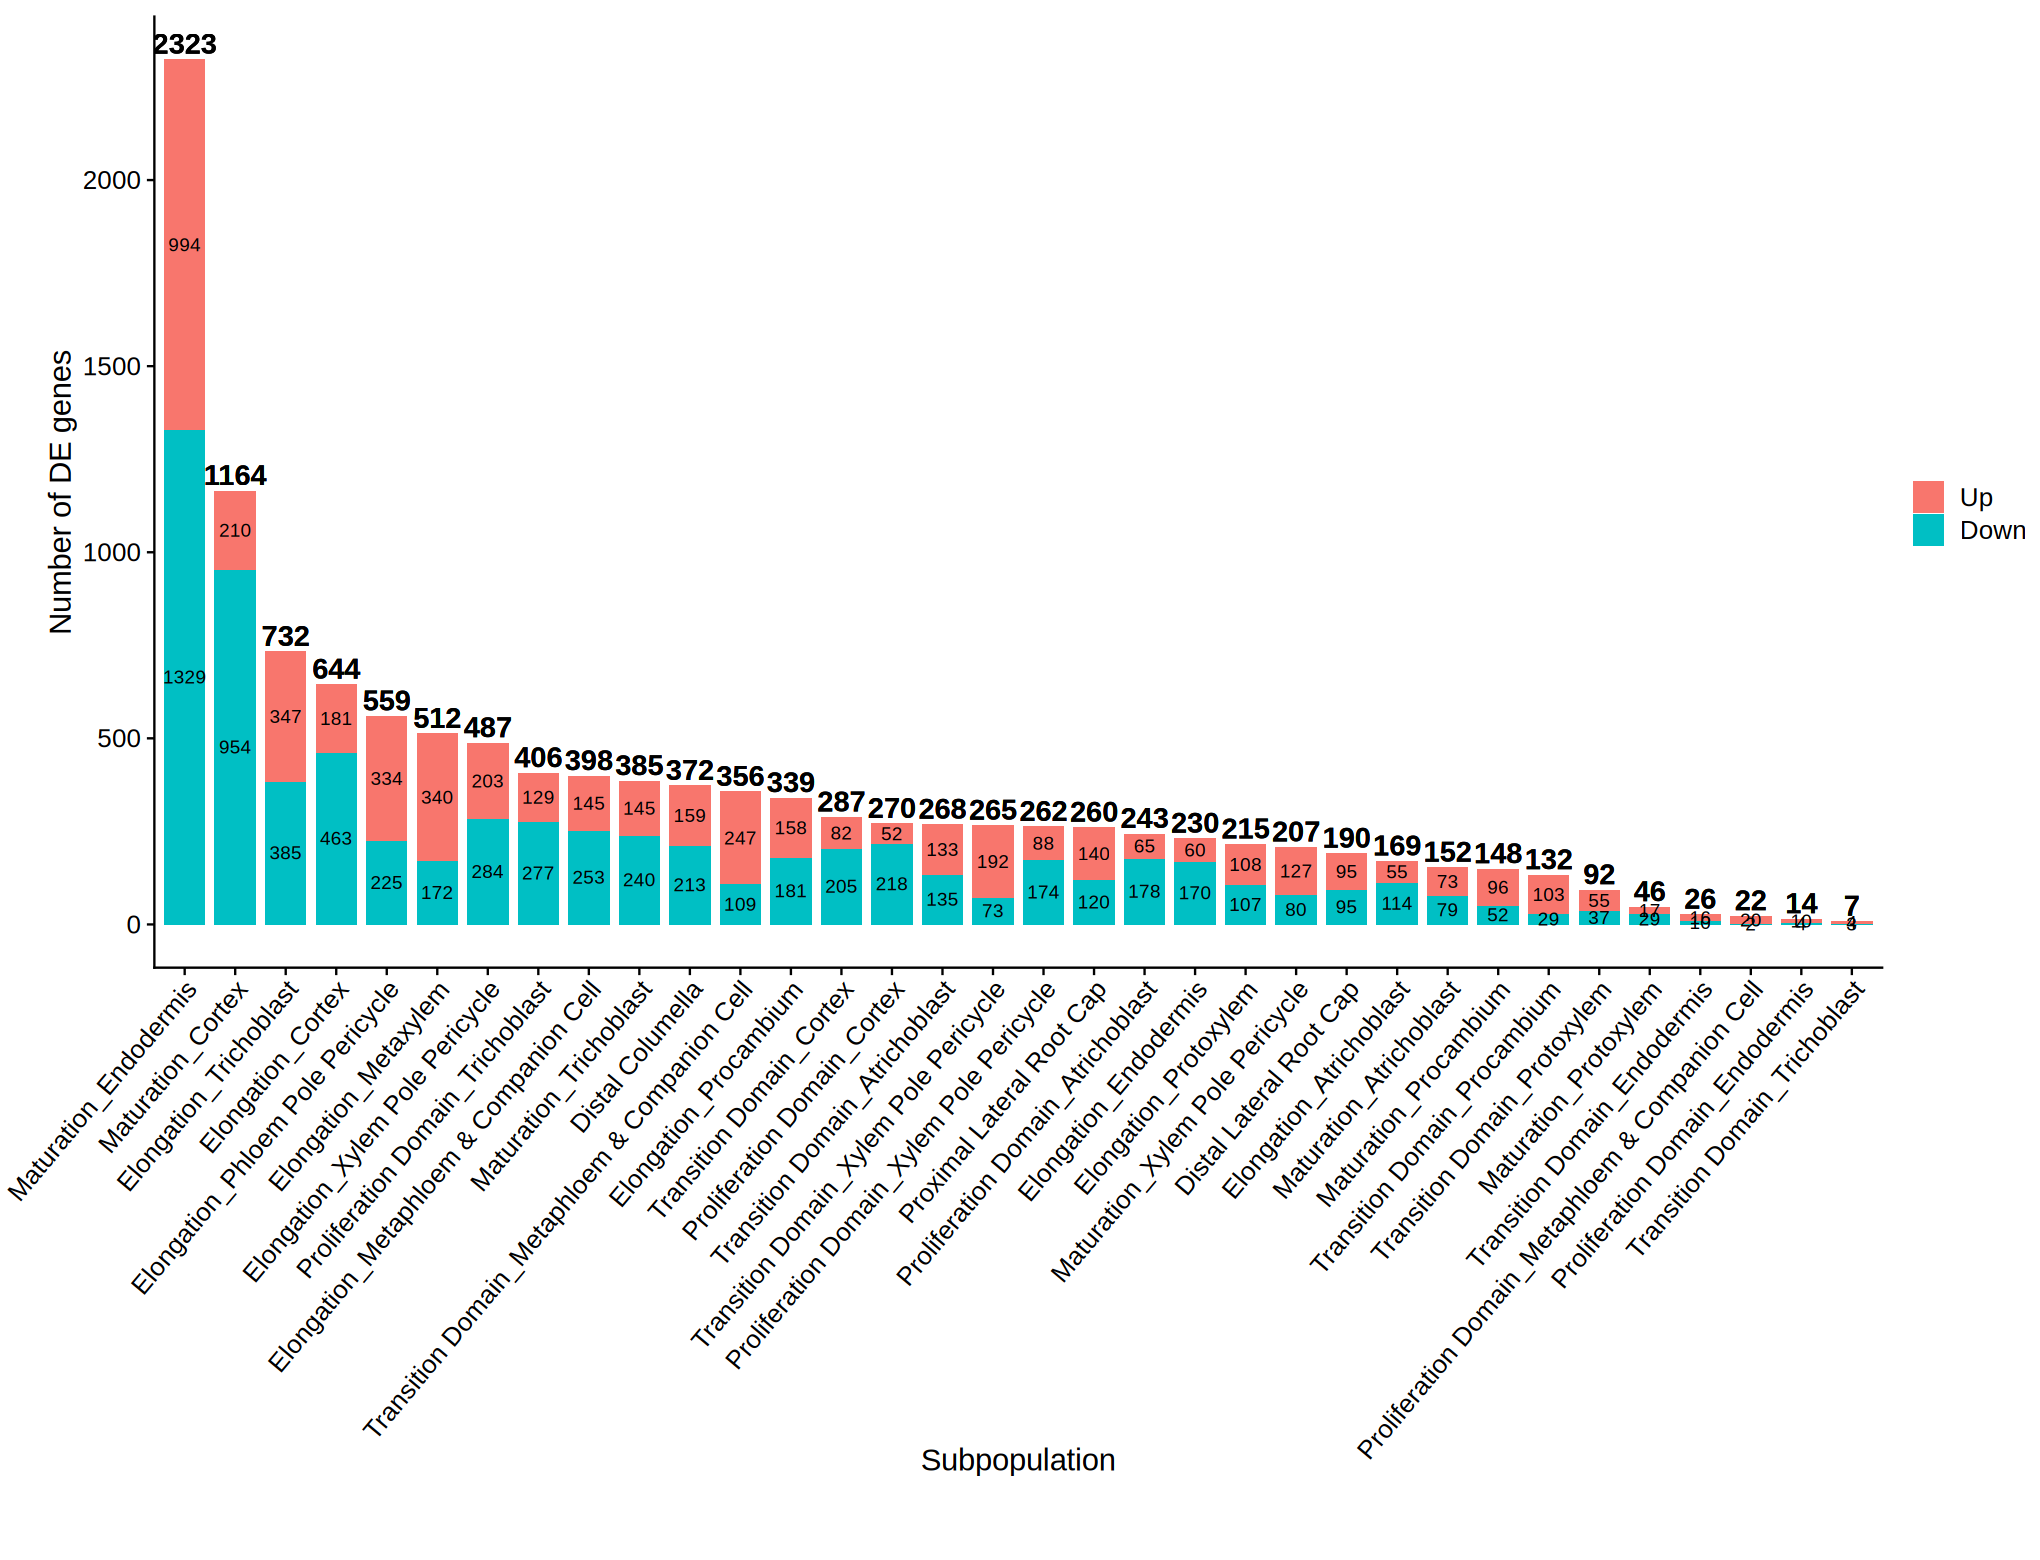

In [95]:
options(repr.plot.width = 17, repr.plot.height = 13)

# Common styling
base_theme <- theme_cowplot(font_size = 18) +
  theme(
    axis.text.x = element_text(
      angle = 50,
      hjust = 1,
      vjust = 1,
      margin = margin(t = 2)
    ),
    plot.title = element_text(hjust = 0.5, face = "bold", size = 20),
    plot.margin = margin(t = 10, r = 10, b = 50, l = 30) 
  )


# Plot
p_new <- nb_genes_per_clust2 %>%
  ggplot(aes(x = fct_reorder(cluster_id, total_n, .desc = TRUE),
             y = n,
             fill = up_dn_label)) +
  geom_bar(stat = "identity", width = 0.8) +
  scale_x_discrete(labels = function(x) sub("___.*", "", x)) +
  ylab("Number of DE genes") +
  xlab("Subpopulation") +
  labs(fill = "") +                 

  # Label for each segment
  geom_text(aes(label = n),
            position = position_stack(vjust = 0.5),
            size = 4) +

  # Label for total at bar top
  geom_text(aes(y = total_n, label = total_n),
            vjust = -0.3,
            fontface = "bold",
            size = 6) +

  base_theme


p_new

In [96]:
nb_de_gene_count2 <- sig_DE_fil %>%
  group_by(gene) %>%
  tally(name = "n_clusters_de")

In [97]:
# get number of times a gene is DE across the number of clusters
gene_de_n <- nb_de_gene_count2 %>%
  group_by(n_clusters_de) %>%
  tally()

total_de_gene_number <- length(unique(sig_DE_fil$gene))
total_de_gene_number

[1] 5466

In [98]:
# Bin the genes with > 9 cell types
gene_de_binned <- gene_de_n %>%
  mutate(
    n_clusters_de_bin =
      ifelse(n_clusters_de >= 15, "15+", as.character(n_clusters_de))
  ) %>%
  group_by(n_clusters_de_bin) %>%
  summarise(n = sum(n), .groups = "drop") %>%
  mutate(
    # order numerically, with 9+ at the end
    n_clusters_de_bin = factor(
      n_clusters_de_bin,
      levels = c(as.character(1:15), "15+")
    )
  )

In [99]:
head(gene_de_binned, 3)

n_clusters_de_bin,n
<fct>,<int>
1,3076
10,22
11,19


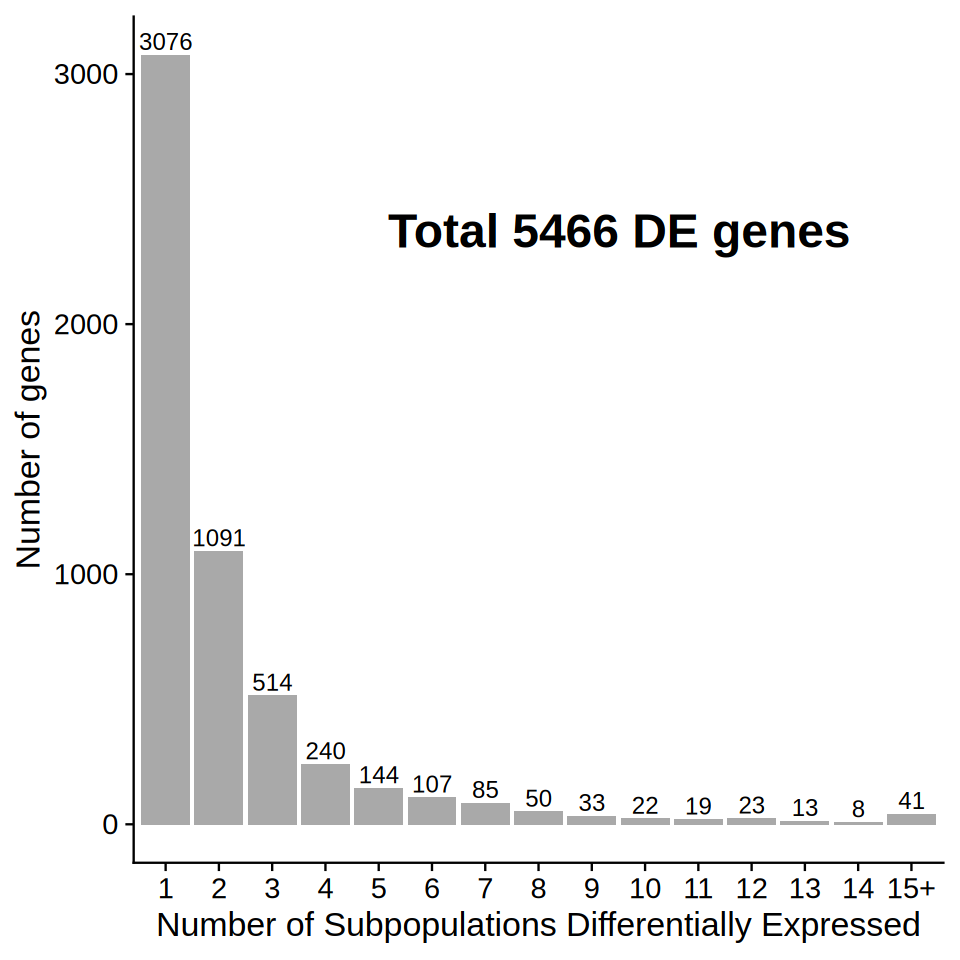

In [100]:
options(repr.plot.width = 8, repr.plot.height = 8)

# Shared theme
base_theme2 <- theme_cowplot(font_size = 20) +
  theme(
    axis.text.x = element_text(angle = 0),
    plot.title   = element_text(hjust = 0.5, face = "bold", size = 20)
  )

p2_count <- gene_de_binned %>%
  ggplot(aes(x = n_clusters_de_bin, y = n)) +
  geom_bar(stat = "identity", fill = "darkgrey") +
  annotate("text",
           x = Inf, y = Inf,
           label = paste0("Total ", total_de_gene_number, " DE genes"),
           hjust = 1.2, vjust =7,
           size = 10, fontface = "bold") +
  geom_text(aes(label = n), vjust = -0.3, size = 5) +
  xlab("Number of Subpopulations Differentially Expressed") +
  ylab("Number of genes") +
  base_theme2

p2_count

In [101]:
head(nb_de_gene_count, 3)

gene,up_dn_label,n_clusters_de
<chr>,<chr>,<int>
AT1G01010,Down,1
AT1G01020,Down,1
AT1G01050,Up,1


In [102]:
nb_genes_per_clust$up_dn_label <- factor(nb_genes_per_clust$up_dn_label, 
                                         levels = c("Up", "Down"))

In [103]:
nb_genes_per_clust3 <- nb_genes_per_clust %>%
  mutate(cluster_group = paste(cluster_id, up_dn_label, sep = "___")) %>%
  group_by(up_dn_label) %>%
  arrange(desc(n), .by_group = TRUE) %>%
  mutate(cluster_group = factor(cluster_group, levels = unique(cluster_group))) %>%
  ungroup()

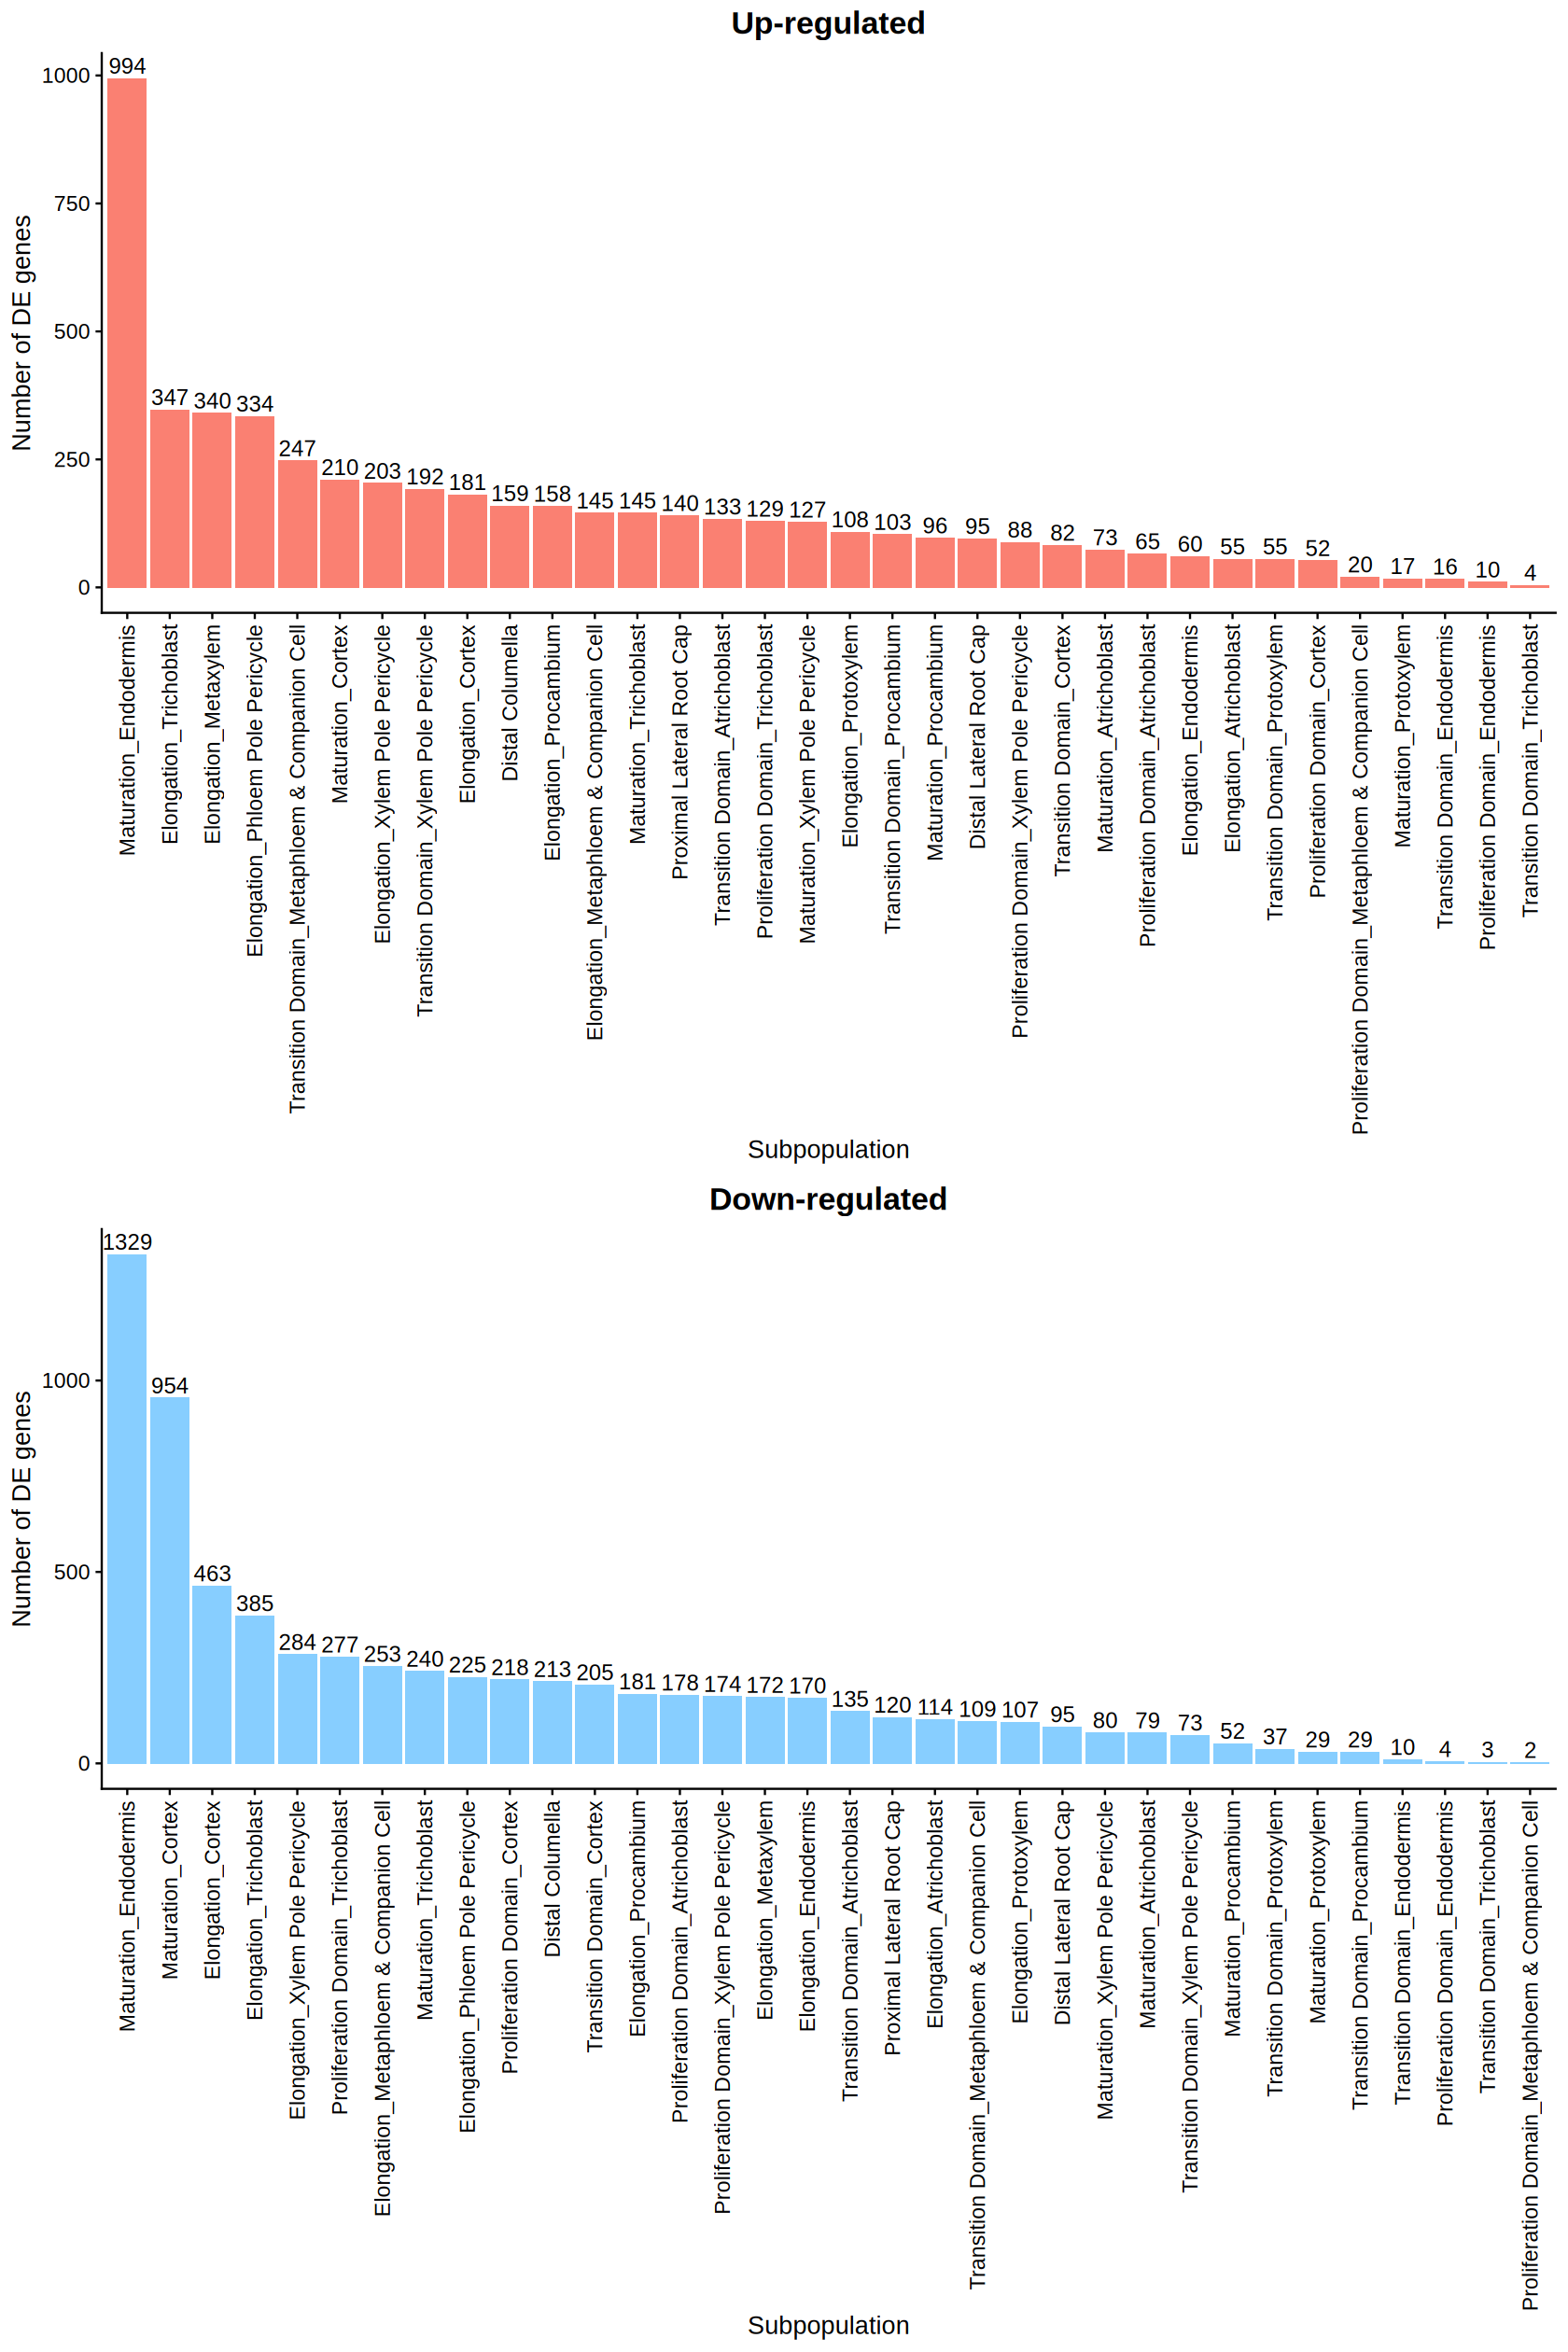

In [104]:
options(repr.plot.width = 14, repr.plot.height = 21)

# Common styling
base_theme <- theme_cowplot(font_size = 16) +
  theme(
    axis.text.x = element_text(angle = 90, hjust = 1, vjust = 0.5),
    plot.title = element_text(hjust = 0.5, face = "bold", size = 20)
  )

# --- Up-regulated plot ---
p_up <- nb_genes_per_clust3 %>%
  filter(up_dn_label == "Up") %>%
  ggplot(aes(x = cluster_group, y = n)) +
  geom_bar(stat = "identity", fill = "salmon") +
  scale_x_discrete(labels = function(x) sub("___.*", "", x)) +
  ylab("Number of DE genes") +
  xlab("Subpopulation") +
  ggtitle("Up-regulated") +
  geom_text(aes(label = n), vjust = -0.3, size = 5) +
  base_theme

# --- Down-regulated plot ---
p_down <- nb_genes_per_clust3 %>%
  filter(up_dn_label == "Down") %>%
  ggplot(aes(x = cluster_group, y = n)) +
  geom_bar(stat = "identity", fill = "#87CEFF") +
  scale_x_discrete(labels = function(x) sub("___.*", "", x)) +
  ylab("Number of DE genes") +
  xlab("Subpopulation") +
  ggtitle("Down-regulated") +
  geom_text(aes(label = n), vjust = -0.3, size = 5) +
  base_theme

# Combine vertically
nb_p_combined <- plot_grid(p_up, p_down, ncol = 1, align = "v", rel_heights = c(1, 1))

nb_p_combined


### Number of genes

In [105]:
# get number of times a gene is DE across the number of clusters
gene_de_n <- nb_de_gene_count %>%
  group_by(n_clusters_de, up_dn_label) %>%
  tally()

gene_de_n$highlight <- c("yes", rep("no", (nrow(gene_de_n)-1)))

total_de_gene_number_up <- length(unique(sig_DE_fil$gene[sig_DE_fil$up_dn_label == "Up"]))
total_de_gene_number_down <- length(unique(sig_DE_fil$gene[sig_DE_fil$up_dn_label == "Down"]))

total_de_gene_number_label_up <- paste(total_de_gene_number_up, "\n Total DE genes", sep = " ")
total_de_gene_number_label_down <- paste(total_de_gene_number_down, "\n Total DE genes", sep = " ")


In [106]:
total_de_gene_number_label_up
total_de_gene_number_label_down

[1] "3027 \n Total DE genes"

[1] "3295 \n Total DE genes"

In [107]:
head(gene_de_n, 3)

n_clusters_de,up_dn_label,n,highlight
<int>,<chr>,<int>,<chr>
1,Down,1974,yes
1,Up,2055,no
2,Down,654,no


In [108]:
gene_de_n$up_dn_label <- factor(gene_de_n$up_dn_label, 
                                         levels = c("Up", "Down"))

Warning message:
“Returning more (or less) than 1 row per `summarise()` group was deprecated in dplyr 1.1.0.
ℹ Please use `reframe()` instead.
ℹ When switching from `summarise()` to `reframe()`, remember that `reframe()` always returns an ungrouped data frame and adjust accordingly.”


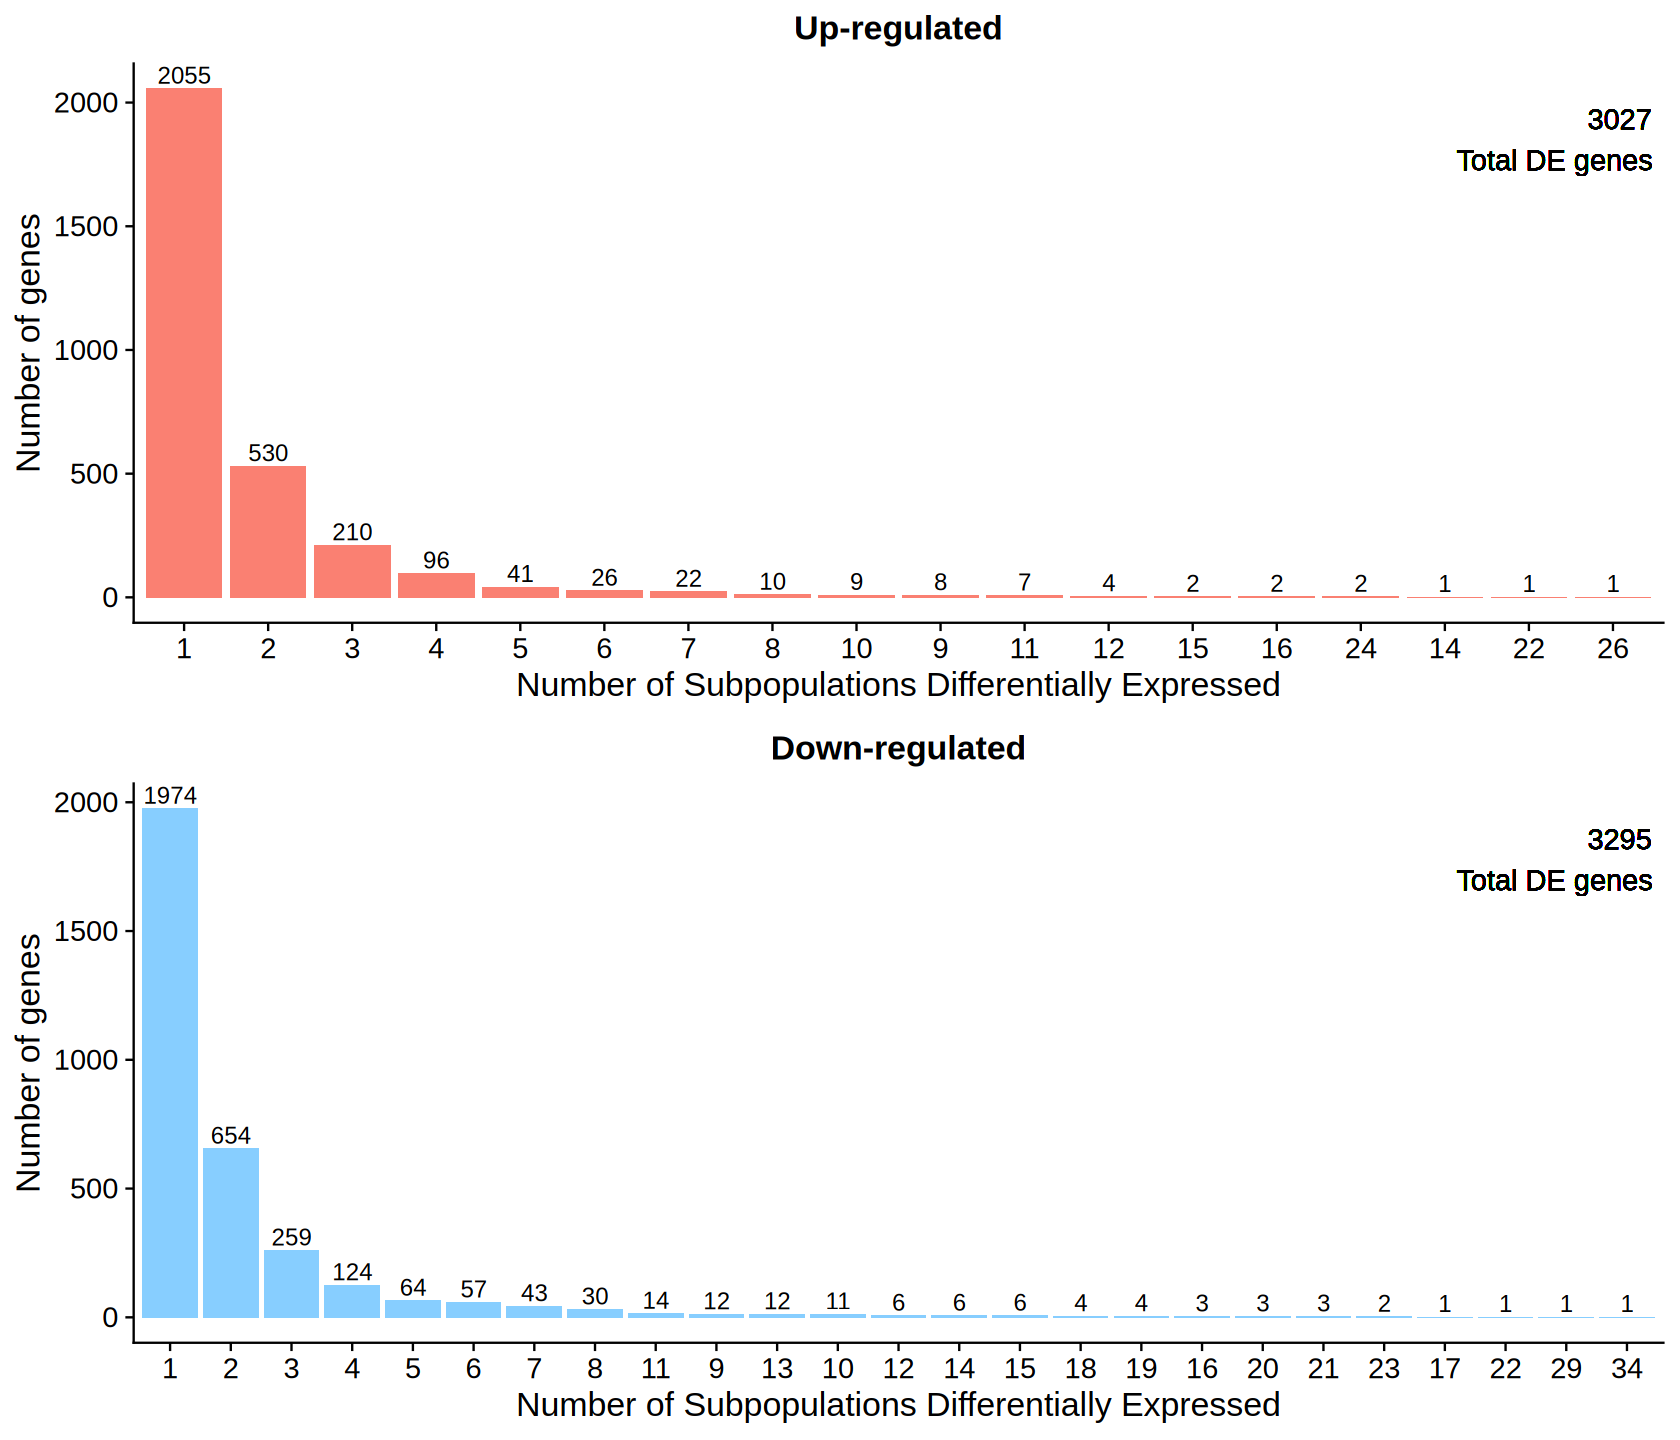

In [109]:
options(repr.plot.width = 14, repr.plot.height = 12)

# Shared theme
base_theme2 <- theme_cowplot(font_size = 20) +
  theme(
    axis.text.x = element_text(angle = 0),
    plot.title   = element_text(hjust = 0.5, face = "bold", size = 20)
  )

# -----------------------
#   DATA FOR ANNOTATION
# -----------------------

ann_df <- gene_de_n %>%
  group_by(up_dn_label) %>%
  summarise(
    x = Inf,
    y = max(n) * 0.90,
    label = case_when(
      up_dn_label == "Up"   ~ total_de_gene_number_label_up,
      up_dn_label == "Down" ~ total_de_gene_number_label_down
    ),
    .groups = "drop"
  )

# -----------------------
#   UP-REGULATED PLOT
# -----------------------

p2_up <- gene_de_n %>%
  filter(up_dn_label == "Up") %>%
  ggplot(aes(x = reorder(n_clusters_de, -n), y = n)) +
  geom_bar(stat = "identity", fill = "salmon") +
  geom_text(aes(label = n), vjust = -0.3, size = 5) +
  geom_text(
    data = filter(ann_df, up_dn_label == "Up"),
    aes(x = x, y = y, label = label),
    inherit.aes = FALSE,
    hjust = 1.05, size = 6
  ) +
  xlab("Number of Subpopulations Differentially Expressed") +
  ylab("Number of genes") +
  ggtitle("Up-regulated") +
  base_theme2

# -----------------------
#   DOWN-REGULATED PLOT
# -----------------------

p2_down <- gene_de_n %>%
  filter(up_dn_label == "Down") %>%
  ggplot(aes(x = reorder(n_clusters_de, -n), y = n)) +
  geom_bar(stat = "identity", fill = "#87CEFF") +
  geom_text(aes(label = n), vjust = -0.3, size = 5) +
  geom_text(
    data = filter(ann_df, up_dn_label == "Down"),
    aes(x = x, y = y, label = label),
    inherit.aes = FALSE,
    hjust = 1.05, size = 6
  ) +
  xlab("Number of Subpopulations Differentially Expressed") +
  ylab("Number of genes") +
  ggtitle("Down-regulated") +
  base_theme2

# -----------------------
#   COMBINE VERTICALLY
# -----------------------

gene_de_plot_combined <- plot_grid(
  p2_up,
  p2_down,
  ncol = 1,
  align = "v",
  rel_heights = c(1, 1)
)

gene_de_plot_combined


### GO analysis: fer4-WT up-regulated genes

In [110]:
sig_DE_fil_up <- sig_DE_fil %>% filter(up_dn_label == "Up")

In [111]:
 # Overlap and GO for all genes 

  markers_sel <- select(sig_DE_fil_up, gene, cluster_id)
  
  markers_list <- split(markers_sel, f=markers_sel$cluster_id)
  
  

In [112]:
#this makes list from long df of gene lists - TARGET is what we want to keep
  markers_list  <- lapply(markers_list, function(x) x[names(x)=="gene"])
  # convert each sublist into character and eliminate duplicates
  markers_list  <- lapply(markers_list, function(x) as.character(unique(x$gene)))
  

In [113]:
# NOTE: lab cluster path below -- change it to your own path
all_bg <- read.csv("/resnick/groups/NolanLab/cchen/Feronia/analysis/muscat_result/20260317_salinity_timecourse_useDateT_noSuspiciousClusters/group_timecelltypeannoLi/fer_4-WT/all_bg.csv")


In [114]:
head(all_bg, 1)

,X,gene,cluster_id,sc_292.cpm,sc_294.cpm,sc_291.cpm,sc_293.cpm,sc_292.frq,sc_294.frq,sc_291.frq,sc_293.frq,fer_4.frq,WT.frq,logFC,logCPM,F,p_val,p_adj.loc,p_adj.glb,contrast
,<int>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
1,1,AT1G01050,Distal Columella,325,302,240,252,0.851,0.787,0.746,0.845,0.817,0.794,0.347,8.14,5.53,0.0187,0.272,0.315,fer_4-WT


In [115]:
 ## GeneOverlap 
  
  # nfeatures RNA
  
  genome_size <- length(unique(all_bg$gene))
  
  #compare all lists
  gom.self <- newGOM(markers_list, markers_list, genome.size=genome_size)
  
  
  int <- getNestedList(gom.self, "intersection")
  int_matrix <- getMatrix(gom.self, "intersection")
  p.val <- getMatrix(gom.self, "pval")
  JC <- getMatrix(gom.self, "Jaccard")

In [116]:
# NOTE: lab cluster path below -- change it to your own path
base_dir <- '/resnick/groups/NolanLab/cchen/Feronia/analysis/muscat_result/20260317_salinity_timecourse_useDateT_noSuspiciousClusters/group_timecelltypeannoLi/fer_4-WT/paper_figs/'


In [117]:
  # log of p.val for intersection
  p.val_log <- -log10(p.val + 1e-200)
  
  tryCatch (
    {
      olap <- Heatmap(p.val_log, name = "-log10_pval", col = colorRamp2(c(0, 200), c("beige", "red")), 
                      column_title = "Number of shared DS genes among cell types", cluster_rows = T,cluster_columns = T, 
                      use_raster= FALSE, show_column_names = TRUE, show_row_names = TRUE, show_row_dend = TRUE, show_column_dend = TRUE, 
                      cell_fun = function(j, i, x, y, width, height, fill) {grid.text(sprintf("%.0f", int_matrix[i, j]), x, y, gp = gpar(fontsize = 10))
                      }) 
      
      # padding - bottom, left, top, right
      
      #pdf(file=paste(base_dir,"Overlap_up.pdf",sep=""), width=18, height=16)
      
      draw(olap, padding = unit(c(5, 5, 5, 10), "mm"), heatmap_legend_side = "left")
      
      dev.off()
    }, error = function(cond) {
      message(paste("URL does not seem to exist:", "url"))
      message("Here's the original error message:")
      message(conditionMessage(cond))
      # Choose a return value in case of error
      NA}, 
    warning = function(cond) {
      message(paste("URL caused a warning:", "url"))
      message("Here's the original warning message:")
      message(conditionMessage(cond))
      # Choose a return value in case of warning
      NULL
    },finally = message("bye")
  )

bye



null device 
          1

In [118]:
  cluster_GO <- gost(markers_list, organism = "athaliana", correction_method = "fdr", significant = F, multi_query = F)
  
  cluster_GO_df <- cluster_GO[[1]]
  
  cluster_GO_sig <- filter(cluster_GO_df, p_value<=0.01)
  
  # top  terms for each cluster
  
  cluster_GO_sig %>%
    filter(source=="GO:BP", intersection_size>=5) %>%
    group_by(query) %>%
    top_n(10, wt = -p_value) %>%
    arrange(desc(p_value)) -> top_GO
  
  GO_n <- cluster_GO_sig %>%
    filter(source=="GO:BP", intersection_size>=5) %>%
    group_by(term_id) %>%
    tally() %>%
    arrange(desc(n))
  
  
  GO_n <- dplyr::rename(GO_n, "n_clusters"=n)
  
  cluster_GO_sig_n <- left_join(cluster_GO_sig, GO_n)
  
  # get all terms for the top ones so that all clusters have values
  
  top_GO_all <- filter(cluster_GO_df, term_id %in% top_GO$term_id)
  

Joining with `by = join_by(term_id)`


In [119]:
head(top_GO_all, 3)

,query,significant,p_value,term_size,query_size,intersection_size,precision,recall,term_id,source,term_name,effective_domain_size,source_order,parents
,<chr>,<lgl>,<dbl>,<int>,<int>,<int>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<int>,<int>,<list>
1,Distal Columella,TRUE,0.004062643,2131,123,29,0.2357724,0.013608634,GO:0009628,GO:BP,response to abiotic stimulus,21925,3535,GO:0050896
2,Distal Columella,TRUE,0.007033256,2940,123,34,0.2764228,0.011564626,GO:0042221,GO:BP,response to chemical,21925,9956,GO:0050896
3,Distal Columella,TRUE,0.007033256,6001,123,55,0.4471545,0.009165139,GO:0050896,GO:BP,response to stimulus,21925,13167,GO:0008150


In [120]:
 #spread and plot
  print("line409")
  tryCatch({
    top_GO_sel <- select(top_GO_all, query, p_value, term_id, term_name)
    
    spread_GO <- spread(top_GO_sel, key = query, p_value)
    
    spread_GO[is.na(spread_GO)] <- 1
    
    spread_GO_m <- as.matrix(-log10(spread_GO[3:ncol(spread_GO)]))
    rownames(spread_GO_m) <- spread_GO$term_name
    print("line419")
    #print(spread_GO_m)
    GO_hm <- Heatmap(spread_GO_m, name = "-log10_pval", 
                     heatmap_legend_param = list(title_position="topcenter", color_bar = "continuous"), 
                     col = colorRamp2(c(0, 20), c("beige", "#e31a1c")), 
                     cluster_rows = T,cluster_columns = T, 
                     clustering_distance_rows = "pearson", clustering_distance_columns = "pearson",
                     use_raster= FALSE, show_column_names = TRUE, show_row_names = TRUE, show_row_dend = FALSE, show_column_dend = FALSE, 
                     row_names_gp = gpar(fontsize = 14), 
                     column_names_gp = gpar(fontsize = 14),
                     show_heatmap_legend = FALSE
                    ) 
  },error = function(cond) NA, warning = function(cond) NULL,finally = {NULL})
  print("line427")

  # create a legend object that matches the heatmap         
  lgd <- Legend(
  col_fun = colorRamp2(c(0, 20), c("beige", "#e31a1c")),
  title = "-log10_pval",
  title_position = "topcenter",
  direction = "vertical"
)
           
 # padding - bottom, left, top, right
tryCatch(
  {
    pdf(file = paste(base_dir, "GO_up_hm.pdf", sep = ""), width = 20, height = 20)

    grid.newpage()
    # 1 row, 2 columns: left = legend, right = heatmap
    pushViewport(viewport(layout = grid.layout(
      nrow = 1, ncol = 2,
      widths = unit.c(unit(3, "cm"), unit(1, "null"))
    )))

    ## --- LEFT: legend ---
    pushViewport(viewport(layout.pos.row = 1, layout.pos.col = 1))
    draw(lgd, x = unit(0.7, "npc"), y = unit(0.5, "npc"),
         just = c("right", "center"))
    popViewport()

    ## --- RIGHT: heatmap ---
    pushViewport(viewport(layout.pos.row = 1, layout.pos.col = 2))
    draw(GO_hm, padding = unit(c(80, 15, 15, 100), "mm"), newpage = FALSE)
    popViewport()

    popViewport()
    dev.off()
  },
  error = function(cond) NA,
  warning = function(cond) NULL,
  finally = { NULL }
)


[1] "line409"
[1] "line419"
[1] "line427"


[1] NA

In [121]:
head(spread_GO_m, 5)

,Distal Columella,Distal Lateral Root Cap,Elongation_Atrichoblast,Elongation_Cortex,Elongation_Endodermis,Elongation_Metaphloem & Companion Cell,Elongation_Metaxylem,Elongation_Phloem Pole Pericycle,Elongation_Procambium,Elongation_Protoxylem,⋯,Proliferation Domain_Xylem Pole Pericycle,Proximal Lateral Root Cap,Transition Domain_Atrichoblast,Transition Domain_Cortex,Transition Domain_Endodermis,Transition Domain_Metaphloem & Companion Cell,Transition Domain_Procambium,Transition Domain_Protoxylem,Transition Domain_Trichoblast,Transition Domain_Xylem Pole Pericycle
response to hypoxia,1.16141618,1.0064337,0.8965981,2.02715614,1.5141519,6.2127337,24.34456098,10.23823190,6.96447885,18.4432187,⋯,2.223583461,1.073841313,5.4754543,1.2552977,0.0000000,7.30883798,13.93468513,6.8701180,0.000000,6.1580906894
immune system process,0.07180757,0.0000000,0.5872915,1.11570162,2.5976057,0.3253161,0.20742266,4.25943563,0.61857522,0.1075115,⋯,0.706092086,0.248104190,0.2394246,0.1813546,0.5353336,0.02298533,0.40118049,0.6950025,0.000000,0.1425265337
generation of precursor metabolites and energy,0.20152129,0.5438362,0.4576939,0.06908926,1.0885369,0.1794545,0.17981958,0.39333241,0.07239312,0.1526659,⋯,0.460995981,0.025274107,0.1294210,0.5441092,0.0000000,1.18615313,0.43666180,0.4654341,0.000000,0.5444653249
purine nucleotide metabolic process,0.11028878,0.0000000,0.3576695,0.00000000,0.7905930,0.2450649,0.00427736,0.20853126,0.32249131,0.0000000,⋯,0.226279281,0.000000000,0.1372021,0.5822219,0.0000000,0.35266778,0.00000000,0.0000000,0.000000,0.0687616560
translation,0.03307599,0.0000000,0.5521210,0.00000000,0.0127811,14.3993987,0.00000000,0.05386527,0.34255847,0.0000000,⋯,0.002560789,0.003956007,0.0000000,0.3157341,0.0000000,0.34773292,0.00113148,0.0000000,0.319059,0.0007070889


In [122]:
spread_GO_m <- spread_GO_m %>%
  as.data.frame() %>%
  rownames_to_column("Go_term")

In [123]:
head(spread_GO_m, 2)

,Go_term,Distal Columella,Distal Lateral Root Cap,Elongation_Atrichoblast,Elongation_Cortex,Elongation_Endodermis,Elongation_Metaphloem & Companion Cell,Elongation_Metaxylem,Elongation_Phloem Pole Pericycle,Elongation_Procambium,⋯,Proliferation Domain_Xylem Pole Pericycle,Proximal Lateral Root Cap,Transition Domain_Atrichoblast,Transition Domain_Cortex,Transition Domain_Endodermis,Transition Domain_Metaphloem & Companion Cell,Transition Domain_Procambium,Transition Domain_Protoxylem,Transition Domain_Trichoblast,Transition Domain_Xylem Pole Pericycle
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,response to hypoxia,1.16141618,1.006434,0.8965981,2.027156,1.514152,6.2127337,24.3445610,10.238232,6.9644789,⋯,2.2235835,1.0738413,5.4754543,1.2552977,0.0000000,7.30883798,13.9346851,6.8701180,0,6.1580907
2,immune system process,0.07180757,0.000000,0.5872915,1.115702,2.597606,0.3253161,0.2074227,4.259436,0.6185752,⋯,0.7060921,0.2481042,0.2394246,0.1813546,0.5353336,0.02298533,0.4011805,0.6950025,0,0.1425265


In [125]:
# Save the GO table
#write.table(spread_GO_m, 
#            "./muscat_result/20260317_salinity_timecourse_useDateT_noSuspiciousClusters/group_timecelltypeannoLi/fer_4-WT/paper_figs/Upregulated_genes_GO_table.txt", sep = "\t", col.names = T, row.names = F, quote = F)


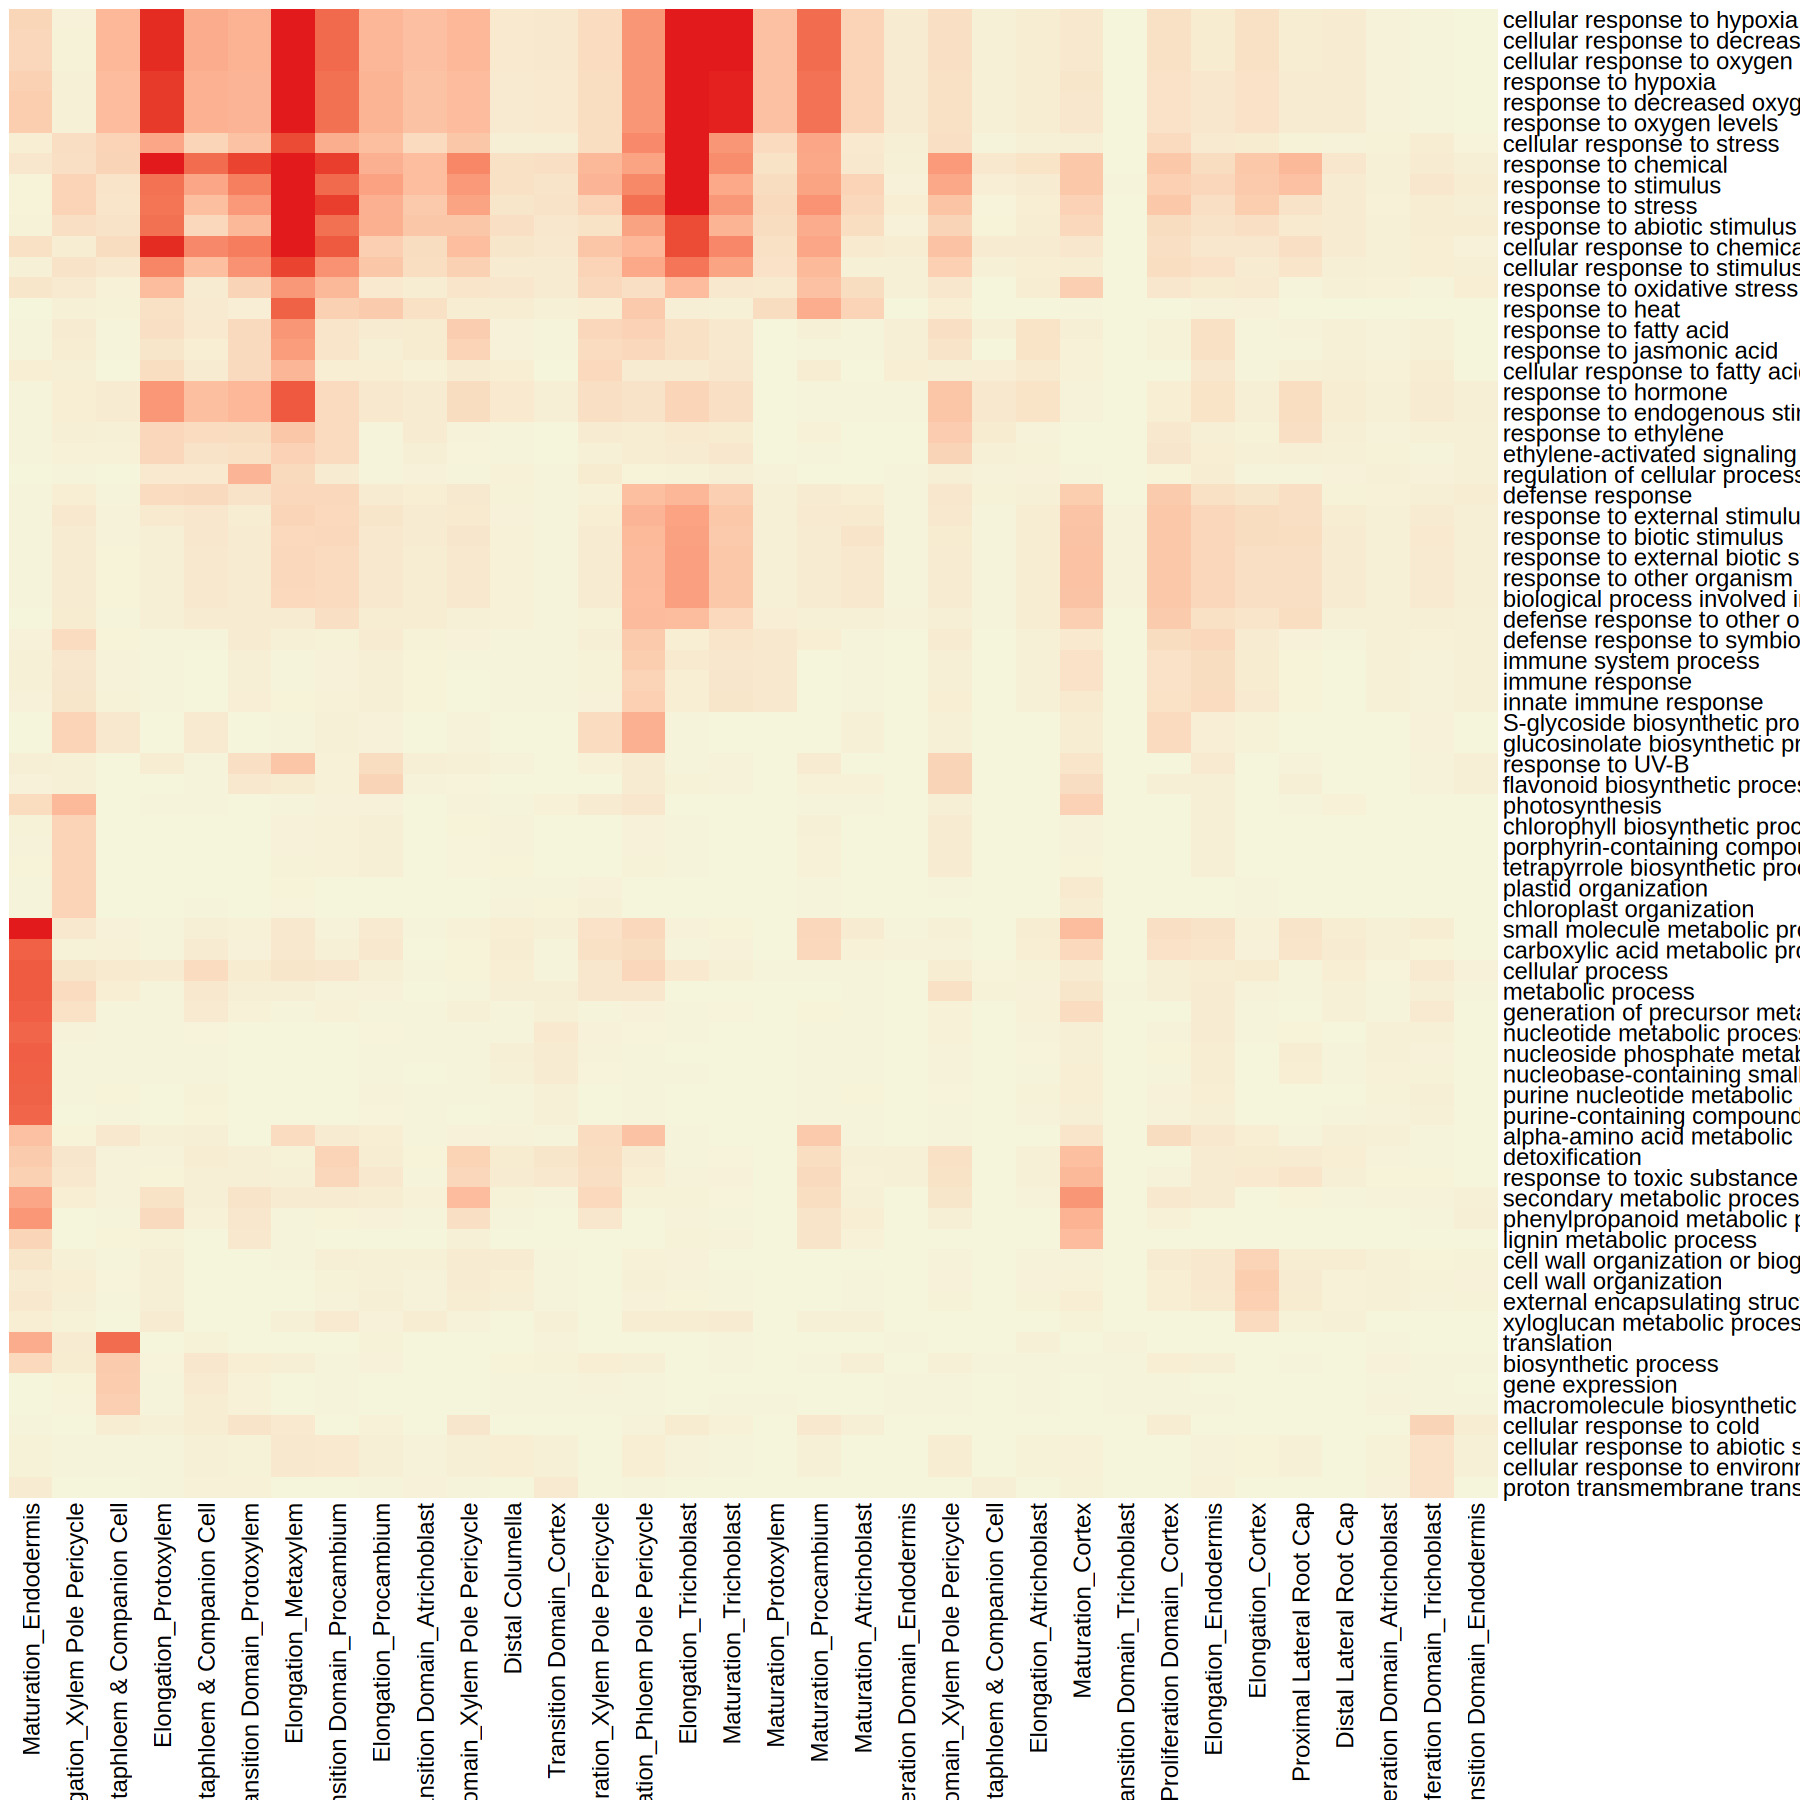

In [126]:
options(repr.plot.width = 15, repr.plot.height = 15)

GO_hm

### GO analysis: fer4-WT down-regulated genes

In [127]:
sig_DE_fil_down <- sig_DE_fil %>% filter(up_dn_label == "Down")

In [128]:
 # Overlap and GO for all genes 

  markers_sel <- select(sig_DE_fil_down, gene, cluster_id)
  
  markers_list <- split(markers_sel, f=markers_sel$cluster_id)
  
  

In [129]:
#this makes list from long df of gene lists - TARGET is what we want to keep
  markers_list  <- lapply(markers_list, function(x) x[names(x)=="gene"])
  # convert each sublist into character and eliminate duplicates
  markers_list  <- lapply(markers_list, function(x) as.character(unique(x$gene)))
  

In [130]:
# NOTE: lab cluster path below -- change it to your own path
all_bg <- read.csv("/resnick/groups/NolanLab/cchen/Feronia/analysis/muscat_result/20260317_salinity_timecourse_useDateT_noSuspiciousClusters/group_timecelltypeannoLi/fer_4-WT/all_bg.csv")


In [131]:
head(all_bg, 1)

,X,gene,cluster_id,sc_292.cpm,sc_294.cpm,sc_291.cpm,sc_293.cpm,sc_292.frq,sc_294.frq,sc_291.frq,sc_293.frq,fer_4.frq,WT.frq,logFC,logCPM,F,p_val,p_adj.loc,p_adj.glb,contrast
,<int>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
1,1,AT1G01050,Distal Columella,325,302,240,252,0.851,0.787,0.746,0.845,0.817,0.794,0.347,8.14,5.53,0.0187,0.272,0.315,fer_4-WT


In [132]:
 ## GeneOverlap 
  
  # nfeatures RNA
  
  genome_size <- length(unique(all_bg$gene))
  
  #compare all lists
  gom.self <- newGOM(markers_list, markers_list, genome.size=genome_size)
  
  
  int <- getNestedList(gom.self, "intersection")
  int_matrix <- getMatrix(gom.self, "intersection")
  p.val <- getMatrix(gom.self, "pval")
  JC <- getMatrix(gom.self, "Jaccard")

In [133]:
# NOTE: lab cluster path below -- change it to your own path
base_dir <- '/resnick/groups/NolanLab/cchen/Feronia/analysis/muscat_result/20260317_salinity_timecourse_useDateT_noSuspiciousClusters/group_timecelltypeannoLi/fer_4-WT/paper_figs/'


In [134]:
  # log of p.val for intersection
  p.val_log <- -log10(p.val + 1e-200)
  
  tryCatch (
    {
      olap <- Heatmap(p.val_log, name = "-log10_pval", col = colorRamp2(c(0, 200), c("beige", "red")), 
                      column_title = "Number of shared DS genes among cell types", cluster_rows = T,cluster_columns = T, 
                      use_raster= FALSE, show_column_names = TRUE, show_row_names = TRUE, show_row_dend = TRUE, show_column_dend = TRUE, 
                      cell_fun = function(j, i, x, y, width, height, fill) {grid.text(sprintf("%.0f", int_matrix[i, j]), x, y, gp = gpar(fontsize = 10))
                      }) 
      
      # padding - bottom, left, top, right
      
      #pdf(file=paste(base_dir,"Overlap_down.pdf",sep=""), width=18, height=16)
      
      draw(olap, padding = unit(c(5, 5, 5, 10), "mm"), heatmap_legend_side = "left")
      
      dev.off()
    }, error = function(cond) {
      message(paste("URL does not seem to exist:", "url"))
      message("Here's the original error message:")
      message(conditionMessage(cond))
      # Choose a return value in case of error
      NA}, 
    warning = function(cond) {
      message(paste("URL caused a warning:", "url"))
      message("Here's the original warning message:")
      message(conditionMessage(cond))
      # Choose a return value in case of warning
      NULL
    },finally = message("bye")
  )

bye



null device 
          1

In [135]:
  cluster_GO <- gost(markers_list, organism = "athaliana", correction_method = "fdr", significant = F, multi_query = F)
  
  cluster_GO_df <- cluster_GO[[1]]
  
  cluster_GO_sig <- filter(cluster_GO_df, p_value<=0.01)
  
  # top  terms for each cluster
  
  cluster_GO_sig %>%
    filter(source=="GO:BP", intersection_size>=5) %>%
    group_by(query) %>%
    top_n(10, wt = -p_value) %>%
    arrange(desc(p_value)) -> top_GO
  
  GO_n <- cluster_GO_sig %>%
    filter(source=="GO:BP", intersection_size>=5) %>%
    group_by(term_id) %>%
    tally() %>%
    arrange(desc(n))
  
  
  GO_n <- dplyr::rename(GO_n, "n_clusters"=n)
  
  cluster_GO_sig_n <- left_join(cluster_GO_sig, GO_n)
  
  # get all terms for the top ones so that all clusters have values
  
  top_GO_all <- filter(cluster_GO_df, term_id %in% top_GO$term_id)
  

Joining with `by = join_by(term_id)`


In [136]:
head(top_GO_all, 3)

,query,significant,p_value,term_size,query_size,intersection_size,precision,recall,term_id,source,term_name,effective_domain_size,source_order,parents
,<chr>,<lgl>,<dbl>,<int>,<int>,<int>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<int>,<int>,<list>
1,Distal Columella,TRUE,6.244532e-18,2940,165,71,0.43030303,0.02414966,GO:0042221,GO:BP,response to chemical,21925,9956,GO:0050896
2,Distal Columella,TRUE,8.438285e-16,31,165,12,0.07272727,0.38709677,GO:0006833,GO:BP,water transport,21925,2496,GO:0042044
3,Distal Columella,TRUE,8.438285e-16,31,165,12,0.07272727,0.38709677,GO:0042044,GO:BP,fluid transport,21925,9845,GO:0006810


In [137]:
 #spread and plot
  print("line409")
  tryCatch({
    top_GO_sel <- select(top_GO_all, query, p_value, term_id, term_name)
    
    spread_GO <- spread(top_GO_sel, key = query, p_value)
    
    spread_GO[is.na(spread_GO)] <- 1
    
    spread_GO_m <- as.matrix(-log10(spread_GO[3:ncol(spread_GO)]))
    rownames(spread_GO_m) <- spread_GO$term_name
    print("line419")
    #print(spread_GO_m)
    GO_hm <- Heatmap(spread_GO_m, name = "-log10_pval", 
                     heatmap_legend_param = list(title_position="topcenter", color_bar = "continuous"), 
                     col = colorRamp2(c(0, 20), c("beige", "#e31a1c")), 
                     cluster_rows = T,cluster_columns = T, 
                     clustering_distance_rows = "pearson", clustering_distance_columns = "pearson",
                     use_raster= FALSE, show_column_names = TRUE, show_row_names = TRUE, show_row_dend = FALSE, show_column_dend = FALSE, 
                     row_names_gp = gpar(fontsize = 14), 
                     column_names_gp = gpar(fontsize = 14),
                     show_heatmap_legend = FALSE
                    ) 
  },error = function(cond) NA, warning = function(cond) NULL,finally = {NULL})
  print("line427")

  # create a legend object that matches the heatmap         
  lgd <- Legend(
  col_fun = colorRamp2(c(0, 20), c("beige", "#e31a1c")),
  title = "-log10_pval",
  title_position = "topcenter",
  direction = "vertical"
)
           
 # padding - bottom, left, top, right
tryCatch(
  {
    pdf(file = paste(base_dir, "GO_down_hm.pdf", sep = ""), width = 20, height = 20)

    grid.newpage()
    # 1 row, 2 columns: left = legend, right = heatmap
    pushViewport(viewport(layout = grid.layout(
      nrow = 1, ncol = 2,
      widths = unit.c(unit(3, "cm"), unit(1, "null"))
    )))

    ## --- LEFT: legend ---
    pushViewport(viewport(layout.pos.row = 1, layout.pos.col = 1))
    draw(lgd, x = unit(0.7, "npc"), y = unit(0.5, "npc"),
         just = c("right", "center"))
    popViewport()

    ## --- RIGHT: heatmap ---
    pushViewport(viewport(layout.pos.row = 1, layout.pos.col = 2))
    draw(GO_hm, padding = unit(c(80, 15, 15, 100), "mm"), newpage = FALSE)
    popViewport()

    popViewport()
    dev.off()
  },
  error = function(cond) NA,
  warning = function(cond) NULL,
  finally = { NULL }
)


[1] "line409"
[1] "line419"
[1] "line427"


pdf 
  2

In [138]:
head(spread_GO_m, 5)

,Distal Columella,Distal Lateral Root Cap,Elongation_Atrichoblast,Elongation_Cortex,Elongation_Endodermis,Elongation_Metaphloem & Companion Cell,Elongation_Metaxylem,Elongation_Phloem Pole Pericycle,Elongation_Procambium,Elongation_Protoxylem,⋯,Proliferation Domain_Xylem Pole Pericycle,Proximal Lateral Root Cap,Transition Domain_Atrichoblast,Transition Domain_Cortex,Transition Domain_Endodermis,Transition Domain_Metaphloem & Companion Cell,Transition Domain_Procambium,Transition Domain_Protoxylem,Transition Domain_Trichoblast,Transition Domain_Xylem Pole Pericycle
response to acid chemical,4.165572,2.0258437,0.3108819,1.6836952,1.3264180,2.397400,0.41308248,0.4427842,1.0615484,1.007642,⋯,14.4636885,1.2880098,1.700609,4.655375,1.291574,3.7869991,0.3414537,1.889030,0.0000000,1.2846133
response to hypoxia,1.233306,0.1770359,0.6980625,0.7377086,0.6763397,1.289725,0.06447662,0.8227721,0.7461082,0.141285,⋯,1.4362347,0.3506105,1.653145,5.741908,0.000000,0.1415457,0.0000000,0.000000,0.0000000,0.2655133
water transport,15.073746,15.1899297,0.0000000,0.2565537,1.1234063,8.952262,3.77779553,1.8954258,5.4476981,8.481615,⋯,1.0670020,11.7934242,1.132357,6.880327,1.281136,8.6154368,0.8192036,5.665306,0.0000000,2.2497066
response to stress,9.950209,2.8698579,0.7062071,2.2392599,1.8356359,4.873268,3.56834554,0.8976685,2.2361478,2.152062,⋯,9.8273112,2.5755571,1.708058,7.218662,1.305789,4.4765419,0.4701228,1.835883,0.3414458,1.0611567
response to oxidative stress,8.800767,4.1801390,0.3414017,1.3552909,1.8111464,2.648908,1.44446322,0.6392931,1.3785083,1.049163,⋯,0.6647881,0.6013706,1.386392,3.047631,0.000000,1.4702926,0.0000000,0.000000,0.0000000,0.0000000


In [139]:
spread_GO_m <- spread_GO_m %>%
  as.data.frame() %>%
  rownames_to_column("Go_term")

In [140]:
head(spread_GO_m, 2)

,Go_term,Distal Columella,Distal Lateral Root Cap,Elongation_Atrichoblast,Elongation_Cortex,Elongation_Endodermis,Elongation_Metaphloem & Companion Cell,Elongation_Metaxylem,Elongation_Phloem Pole Pericycle,Elongation_Procambium,⋯,Proliferation Domain_Xylem Pole Pericycle,Proximal Lateral Root Cap,Transition Domain_Atrichoblast,Transition Domain_Cortex,Transition Domain_Endodermis,Transition Domain_Metaphloem & Companion Cell,Transition Domain_Procambium,Transition Domain_Protoxylem,Transition Domain_Trichoblast,Transition Domain_Xylem Pole Pericycle
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,response to acid chemical,4.165572,2.0258437,0.3108819,1.6836952,1.3264180,2.397400,0.41308248,0.4427842,1.0615484,⋯,14.463689,1.2880098,1.700609,4.655375,1.291574,3.7869991,0.3414537,1.88903,0,1.2846133
2,response to hypoxia,1.233306,0.1770359,0.6980625,0.7377086,0.6763397,1.289725,0.06447662,0.8227721,0.7461082,⋯,1.436235,0.3506105,1.653145,5.741908,0.000000,0.1415457,0.0000000,0.00000,0,0.2655133


In [141]:
# Save the GO table
write.table(spread_GO_m, 
            "./muscat_result/20260317_salinity_timecourse_useDateT_noSuspiciousClusters/group_timecelltypeannoLi/fer_4-WT/paper_figs/Downregulated_genes_GO_table.txt", sep = "\t", col.names = T, row.names = F, quote = F)


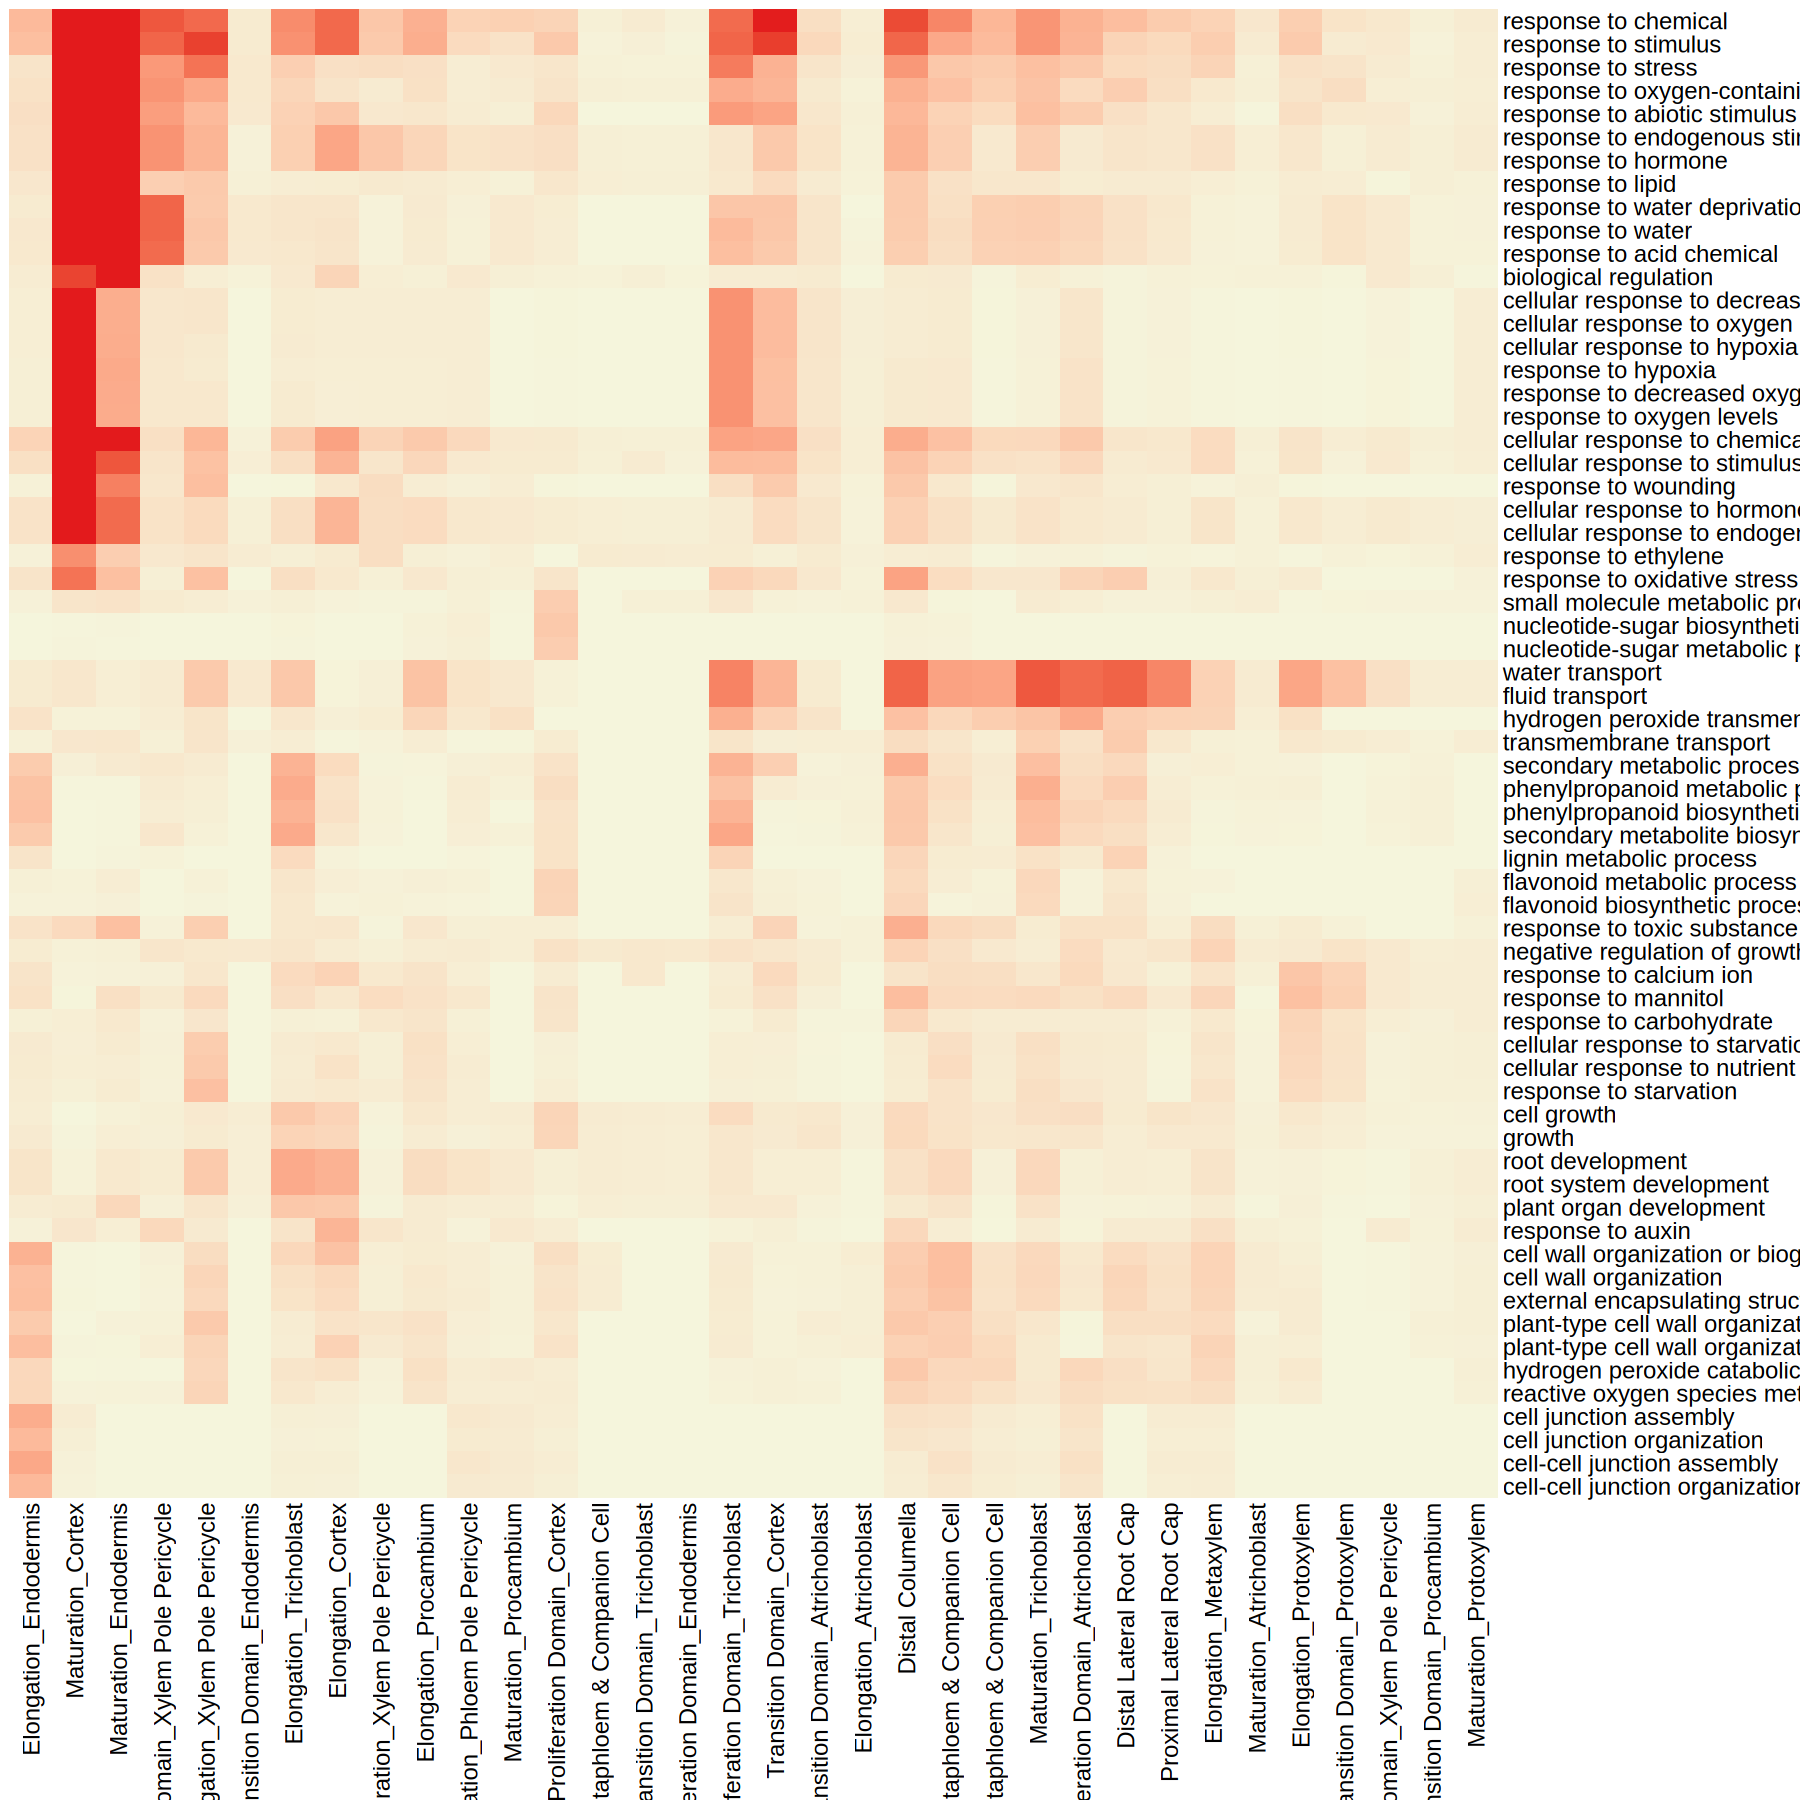

In [142]:
options(repr.plot.width = 15, repr.plot.height = 15)

GO_hm